# Avaliação final independente — Random Forest

Este notebook trata **Random Forest como o único modelo selecionado do projeto**. Ele não cria ranking, não compara algoritmos e não depende dos notebooks finais dos demais modelos.

O notebook recupera exclusivamente os hiperparâmetros já escolhidos na Fase 6, treina com todo o conjunto de desenvolvimento e realiza uma única avaliação detalhada no teste reservado.

> A configuração selecionada na Fase 6 é congelada antes do acesso ao teste.


## 1. Escopo e cautela metodológica

- O teste é utilizado neste notebook como avaliação final deste caminho hipotético.
- Não ajuste hiperparâmetros, features ou limiar com base nos resultados do teste.
- `id_escola` e `chave_escola_ano` permanecem apenas como rastreabilidade e nunca entram no modelo.
- As interpretações são associativas e preditivas, não causais.


## Inicialização independente

Esta célula reproduz a configuração compartilhada do notebook principal. Ela prepara ambiente, caminhos e funções comuns sem alterar a lógica canônica desta etapa.


In [1]:
# =============================================================================
# CONFIGURAÇÕES PARA RODAR O NOTEBOOK
# Execute esta célula primeiro. Esta política não altera a metodologia do fluxo.
# =============================================================================
import os
import sys
import gc
import ctypes
import polars as pl
from datetime import datetime, timezone

# Opções do usuário
PERFIL_RECURSOS = "auto"       # auto | baixo | medio | normal | alto
LIMITE_RAM_PERCENTUAL = None    # None = automático; ou inteiro entre 50 e 90
MAX_THREADS = None              # None = automático; ou inteiro >= 1
USAR_GPU = os.getenv("TC3_USAR_GPU", "1").strip().lower() in {"1", "true", "sim", "yes"}                 # requer WSL2 + RAPIDS/cuML + kernel tc3-gpu

REUTILIZAR_ARTEFATOS = False  # False reconstrói; True aceita caches válidos
SALVAR_ARTEFATOS = True       # False usa somente área temporária da sessão


# Protocolo metodologico compartilhado por todas as fases e modelos.
SEED_GLOBAL = 42
EXECUTAR_SHAP = os.getenv("TC3_EXECUTAR_SHAP", "0").strip().lower() in {"1", "true", "sim", "yes"}
AMOSTRA_SHAP = max(20, int(os.getenv("TC3_AMOSTRA_SHAP", "100")))
AMOSTRA_BACKGROUND_SHAP = max(20, int(os.getenv("TC3_BACKGROUND_SHAP", "50")))
CHAVE_GRUPO_GLOBAL = "chave_escola_ano"
N_SPLITS_CV_GLOBAL = 3
N_ITER_BUSCA_GLOBAL = 10
LIMIAR_CLASSIFICACAO_GLOBAL = 0.50
REPETICOES_PERMUTACAO_GLOBAL = 5
REPETICOES_BOOTSTRAP_GLOBAL = 200

N_JOBS_MODELAGEM_GLOBAL = 1
N_SPLITS_HOLDOUT_GLOBAL = 1
SCORING_PRINCIPAL_GLOBAL = "roc_auc"
VERBOSE_BUSCA_GLOBAL = 2
ERRO_BUSCA_GLOBAL = "raise"
RETORNAR_SCORE_TREINO_GLOBAL = True

# Contrato comum de pre-processamento dos modelos.
IMPUTACAO_NUMERICA_GLOBAL = "median"
IMPUTACAO_CATEGORICA_GLOBAL = "most_frequent"
ONE_HOT_DESCONHECIDO_GLOBAL = "ignore"
ONE_HOT_SPARSO_GLOBAL = False  # matriz densa: evita fallback dos modelos para CPU
SPARSE_THRESHOLD_GLOBAL = 0.0
ESCALONADOR_CENTRALIZAR_GLOBAL = False


# Percentuais de amostragem (0 < valor <= 1). Alterar aqui afeta todo o notebook.
# O teste final permanece integral (100%); as amostras menores servem apenas ao
# desenvolvimento, comparacao de modelos e interpretabilidade.
FRACOES_AMOSTRAGEM = {
    "eda_correlacao": 0.05,
    "validacao_preparacao": 0.02,
    "fase5_modelos": 0.10,
    "fase5_knn": 0.02,  # KNN tem custo de memoria e predicao maior.
    "fase6_desenvolvimento": 0.12,
    "fase6_validacao_interna": 0.25,
    "fase7_desenvolvimento": 1.00,
    "fase7_teste": 1.00,
    "interpretacao": 0.035,
    "bootstrap": 0.17,
}

for _nome, _fracao in FRACOES_AMOSTRAGEM.items():
    if not 0 < _fracao <= 1:
        raise ValueError(f"Fracao invalida em FRACOES_AMOSTRAGEM[{_nome!r}]: {_fracao}")


def tamanho_por_fracao(total, fracao):
    """Converte uma proporcao em quantidade reproduzivel, sem exceder o total."""
    if total < 1:
        raise ValueError("Nao e possivel amostrar uma particao vazia.")
    return min(total, max(1, round(total * fracao)))


def materializar_split_percentual(dados, contrato, nome_split, fracao, seed, materializador):
    """Materializa uma fracao de um split e informa claramente o universo usado."""
    import polars as pl

    coluna_split = contrato["controle_split"]
    total = (
        dados.filter(pl.col(coluna_split) == nome_split)
        .select(pl.len().alias("total"))
        .collect()
        .item()
    )
    quantidade = tamanho_por_fracao(total, fracao)
    X, y = materializador(dados, contrato, nome_split, limit=quantidade, seed=seed)
    print(f"{nome_split}: {quantidade:,}/{total:,} registros ({fracao:.1%})")
    return X, y


def _estado_memoria_sistema():
    """Retorna RAM total e disponível em bytes."""
    valores = {}
    try:
        with open("/proc/meminfo", encoding="utf-8") as arquivo:
            for linha in arquivo:
                chave, valor = linha.split(":", 1)
                valores[chave] = int(valor.strip().split()[0]) * 1024
        return valores["MemTotal"], valores.get("MemAvailable", valores.get("MemFree", 0))
    except (OSError, KeyError, ValueError):
        try:
            return (
                os.sysconf("SC_PHYS_PAGES") * os.sysconf("SC_PAGE_SIZE"),
                os.sysconf("SC_AVPHYS_PAGES") * os.sysconf("SC_PAGE_SIZE"),
            )
        except (AttributeError, OSError, ValueError):
            return None, None


RAM_TOTAL_BYTES, RAM_DISPONIVEL_BYTES = _estado_memoria_sistema()
RAM_TOTAL_GB = RAM_TOTAL_BYTES / 1024**3 if RAM_TOTAL_BYTES else 0.0
CPUS_LOGICAS = os.cpu_count() or 1

if RAM_TOTAL_GB and RAM_TOTAL_GB <= 4.5:
    _perfil_detectado = "baixo"
elif RAM_TOTAL_GB and RAM_TOTAL_GB <= 8.5:
    _perfil_detectado = "medio"
elif RAM_TOTAL_GB and RAM_TOTAL_GB <= 16.5:
    _perfil_detectado = "normal"
else:
    _perfil_detectado = "alto"

_perfis = {
    "baixo": (60, 1),
    "medio": (70, min(2, CPUS_LOGICAS)),
    "normal": (75, min(4, CPUS_LOGICAS)),
    "alto": (80, min(8, max(1, CPUS_LOGICAS // 2))),
}
PERFIL_ATIVO = _perfil_detectado if PERFIL_RECURSOS == "auto" else PERFIL_RECURSOS.lower()
if PERFIL_ATIVO not in _perfis:
    raise ValueError("PERFIL_RECURSOS deve ser auto, baixo, medio, normal ou alto.")

_limite_perfil, _threads_perfil = _perfis[PERFIL_ATIVO]
LIMITE_RAM_ATIVO = _limite_perfil if LIMITE_RAM_PERCENTUAL is None else int(LIMITE_RAM_PERCENTUAL)
THREADS_MAXIMAS = _threads_perfil if MAX_THREADS is None else int(MAX_THREADS)
if not 50 <= LIMITE_RAM_ATIVO <= 90:
    raise ValueError("LIMITE_RAM_PERCENTUAL deve ficar entre 50 e 90.")
if THREADS_MAXIMAS < 1:
    raise ValueError("MAX_THREADS deve ser pelo menos 1.")
THREADS_MAXIMAS = min(THREADS_MAXIMAS, CPUS_LOGICAS)

# Definido antes de NumPy, Polars, scikit-learn e cuML serem importados.
for _variavel, _valor in {
    "OMP_NUM_THREADS": str(THREADS_MAXIMAS),
    "OPENBLAS_NUM_THREADS": str(THREADS_MAXIMAS),
    "MKL_NUM_THREADS": str(THREADS_MAXIMAS),
    "NUMEXPR_NUM_THREADS": str(THREADS_MAXIMAS),
    "VECLIB_MAXIMUM_THREADS": str(THREADS_MAXIMAS),
    "POLARS_MAX_THREADS": str(THREADS_MAXIMAS),
    "MALLOC_ARENA_MAX": "2",
}.items():
    os.environ[_variavel] = _valor

HISTORICO_RECURSOS = []
_estado_recursos = {"nivel": None, "threads": None, "contexto_threads": None}


def _aplicar_threads(limite):
    """Limita pools BLAS/OpenMP já carregados; Polars usa o limite inicial."""
    limite = max(1, min(int(limite), THREADS_MAXIMAS))
    if _estado_recursos["threads"] == limite:
        return
    anterior = _estado_recursos.get("contexto_threads")
    if anterior is not None:
        try:
            anterior.__exit__(None, None, None)
        except Exception:
            pass
    try:
        from threadpoolctl import threadpool_limits
        contexto = threadpool_limits(limits=limite)
        contexto.__enter__()
    except Exception:
        contexto = None
    _estado_recursos["contexto_threads"] = contexto
    _estado_recursos["threads"] = limite


def _liberar_memoria_global(agressiva=False):
    """Libera caches transitórios sem apagar variáveis usadas pelo fluxo."""
    shell = get_ipython()
    if shell is not None:
        for nome in ("_", "__", "___"):
            shell.user_ns[nome] = None
    gc.collect()
    modulo_cupy = sys.modules.get("cupy")
    if modulo_cupy is not None:
        try:
            modulo_cupy.get_default_memory_pool().free_all_blocks()
            modulo_cupy.get_default_pinned_memory_pool().free_all_blocks()
        except Exception:
            pass
    if agressiva:
        modulo_plt = sys.modules.get("matplotlib.pyplot")
        if modulo_plt is not None:
            try:
                modulo_plt.close("all")
            except Exception:
                pass
        try:
            ctypes.CDLL("libc.so.6").malloc_trim(0)
        except (OSError, AttributeError):
            pass


def _gerenciar_recursos(*_args, **_kwargs):
    """Reduz paralelismo progressivamente e nunca interrompe uma célula."""
    total, disponivel = _estado_memoria_sistema()
    if not total:
        return
    uso = 100.0 * (total - disponivel) / total
    margem = LIMITE_RAM_ATIVO - uso
    if margem > 15:
        nivel, threads, limpar = "normal", THREADS_MAXIMAS, False
    elif margem > 7:
        nivel, threads, limpar = "moderado", max(1, THREADS_MAXIMAS // 2), True
    else:
        nivel, threads, limpar = "conservador", 1, True

    _aplicar_threads(threads)
    if limpar:
        _liberar_memoria_global(agressiva=margem <= 0)

    if nivel != _estado_recursos["nivel"]:
        registro = {
            "instante_utc": datetime.now(timezone.utc).isoformat(),
            "nivel": nivel,
            "threads": threads,
            "ram_usada_percentual": round(uso, 1),
            "ram_disponivel_gb": round(disponivel / 1024**3, 2),
        }
        HISTORICO_RECURSOS.append(registro)
        print(
            f"[recursos] nível={nivel}; threads={threads}; "
            f"RAM usada={uso:.1f}%; livre={disponivel / 1024**3:.1f} GB."
        )
        _estado_recursos["nivel"] = nivel


ipython = get_ipython()
if ipython is not None:
    # Impede callbacks duplicados ao reexecutar a configuração.
    for _atributo in ("_tc3_memory_guard", "_tc3_resource_guard"):
        _guard_anterior = getattr(ipython, _atributo, None)
        if _guard_anterior is not None:
            for _evento, _funcao in _guard_anterior:
                try:
                    ipython.events.unregister(_evento, _funcao)
                except (ValueError, KeyError):
                    pass
    _callbacks_recursos = [
        ("pre_run_cell", _gerenciar_recursos),
        ("post_run_cell", _gerenciar_recursos),
    ]
    for _evento, _funcao in _callbacks_recursos:
        ipython.events.register(_evento, _funcao)
    ipython._tc3_resource_guard = _callbacks_recursos

_gerenciar_recursos()
print(
    "Configuração automática ativa: "
    f"perfil={PERFIL_ATIVO}; RAM={RAM_TOTAL_GB:.1f} GB; CPUs={CPUS_LOGICAS}; "
    f"limite preventivo={LIMITE_RAM_ATIVO}%; threads máximas={THREADS_MAXIMAS}."
)

# Backend GPU: ativado antes de qualquer importação do scikit-learn.
cuda_conda = os.path.join(sys.prefix, "targets", "x86_64-linux")
if os.path.exists(os.path.join(cuda_conda, "include", "cuda.h")):
    os.environ.setdefault("CUDA_PATH", cuda_conda)
if USAR_GPU:
    try:
        from cuml.accel import install
        install(log_level="info")
        import cupy as cp
        dispositivo = cp.cuda.runtime.getDeviceProperties(0)
        nome_gpu = dispositivo["name"].decode() if isinstance(dispositivo["name"], bytes) else str(dispositivo["name"])
        memoria_gpu_gb = cp.cuda.runtime.memGetInfo()[1] / 1024**3
        BACKEND_ML = f"RAPIDS cuML — {nome_gpu} ({memoria_gpu_gb:.1f} GB de VRAM)"
    except Exception as exc:
        raise RuntimeError("GPU/RAPIDS indisponível. Abra no WSL2 e selecione o kernel tc3-gpu.") from exc
else:
    BACKEND_ML = "scikit-learn CPU"
print("Backend de Machine Learning:", BACKEND_ML)

from pathlib import Path
import hashlib
import json
from urllib.error import HTTPError, URLError
from urllib.request import Request, urlopen

def localizar_raiz(inicio: Path) -> Path:
    for candidato in [inicio, *inicio.parents]:
        if (candidato / "dados").is_dir() and (candidato / "notebooks").is_dir():
            return candidato
    raise FileNotFoundError("Execute este notebook dentro do repositório tech_challenge_3.")

PROJECT_ROOT = localizar_raiz(Path.cwd().resolve())
print("Raiz do projeto:", PROJECT_ROOT)


# Contrato único de diretórios. Fontes sempre são lidas da área imutável.
import tempfile

FONTES_ORIGINAIS_DIR = PROJECT_ROOT / "dados" / "fontes_originais"
_TEMP_BASE = PROJECT_ROOT / ".execucao_temporaria"
_TEMP_BASE.mkdir(parents=True, exist_ok=True)
if SALVAR_ARTEFATOS:
    RAIZ_ARTEFATOS = PROJECT_ROOT
    _DIRETORIO_TEMPORARIO = None
else:
    _DIRETORIO_TEMPORARIO = tempfile.TemporaryDirectory(prefix="tc3_", dir=_TEMP_BASE)
    RAIZ_ARTEFATOS = Path(_DIRETORIO_TEMPORARIO.name)

DADOS_PROCESSADOS_DIR = RAIZ_ARTEFATOS / "dados" / "dados_processados"
DADOS_ANALITICOS_DIR = RAIZ_ARTEFATOS / "dados" / "dados_analiticos"
RESULTADOS_DIR = RAIZ_ARTEFATOS / "resultados"
RESULTADOS_FIGURAS_DIR = RESULTADOS_DIR / "figuras"
RESULTADOS_TABELAS_DIR = RESULTADOS_DIR / "tabelas"
RESULTADOS_METRICAS_DIR = RESULTADOS_DIR / "metricas"
RESULTADOS_RELATORIOS_DIR = RESULTADOS_DIR / "relatorios"
MODELOS_DIR = RAIZ_ARTEFATOS / "modelos"

for _diretorio_saida in (
    DADOS_PROCESSADOS_DIR, DADOS_ANALITICOS_DIR, RESULTADOS_FIGURAS_DIR,
    RESULTADOS_TABELAS_DIR, RESULTADOS_METRICAS_DIR,
    RESULTADOS_RELATORIOS_DIR, MODELOS_DIR,
):
    _diretorio_saida.mkdir(parents=True, exist_ok=True)

def deve_recalcular(caminho):
    """True quando o cache deve ser ignorado ou ainda não existe."""
    return not REUTILIZAR_ARTEFATOS or not Path(caminho).exists()


def publicar_parquet_particionado(frame, destino, *, particionar_por):
    """Publica partições sequencialmente e troca o diretório de forma atômica.

    O ``write_parquet(partition_by=...)`` do Polars prepara várias partições em
    paralelo e pode duplicar o pico de RAM de bases já materializadas. Esta
    implementação mantém apenas uma partição adicional em memória por vez.
    """
    import gc
    import shutil

    destino = Path(destino)
    temporario = destino.with_name(destino.name + "__publicacao_tmp")
    anterior = destino.with_name(destino.name + "__publicacao_anterior")
    for caminho in (temporario, anterior):
        if caminho.exists():
            shutil.rmtree(caminho)
    temporario.mkdir(parents=True, exist_ok=True)

    lazy = frame if isinstance(frame, pl.LazyFrame) else frame.lazy()
    schema = lazy.collect_schema()
    if particionar_por not in schema.names():
        raise ValueError(f"Coluna de particionamento ausente: {particionar_por}")

    valores = (
        lazy.select(pl.col(particionar_por).unique())
        .collect(engine="streaming")
        .get_column(particionar_por)
        .to_list()
    )
    valores = sorted(valores, key=lambda valor: (valor is None, str(valor)))
    if not valores:
        raise RuntimeError("Não há valores para particionar a publicação.")

    arquivos_novos = []
    for indice, valor in enumerate(valores):
        valor_hive = "__HIVE_DEFAULT_PARTITION__" if valor is None else str(valor)
        if any(separador in valor_hive for separador in ("/", "\\")):
            raise ValueError(f"Valor de partição inválido: {valor_hive!r}")
        diretorio_particao = temporario / f"{particionar_por}={valor_hive}"
        diretorio_particao.mkdir(parents=True, exist_ok=True)
        arquivo = diretorio_particao / f"part-{indice:05d}.parquet"
        predicado = pl.col(particionar_por).is_null() if valor is None else pl.col(particionar_por) == pl.lit(valor)
        lazy.filter(predicado).sink_parquet(
            arquivo,
            compression="zstd",
            statistics=True,
            row_group_size=100_000,
            mkdir=True,
            engine="streaming",
        )
        if not arquivo.is_file() or arquivo.stat().st_size == 0:
            raise RuntimeError(f"Partição não foi gravada corretamente: {arquivo}")
        arquivos_novos.append(arquivo)
        gc.collect()

    if destino.exists():
        destino.replace(anterior)
    try:
        try:
            temporario.replace(destino)
        except OSError:
            # Volumes Docker montados do Windows podem bloquear rename de diretórios.
            # O fallback copia a publicação pronta e remove a área temporária.
            shutil.copytree(temporario, destino)
            shutil.rmtree(temporario)
    except Exception:
        if destino.exists():
            shutil.rmtree(destino)
        if anterior.exists():
            anterior.replace(destino)
        raise
    if anterior.exists():
        shutil.rmtree(anterior)
    return len(arquivos_novos)


def salvar_figura_eda(figura, nome):
    """Exporta uma figura exploratória sem alterar sua exibição no notebook."""
    destino = RESULTADOS_FIGURAS_DIR / "fluxo_exploratorio" / nome
    destino.parent.mkdir(parents=True, exist_ok=True)
    figura.savefig(destino, dpi=180, bbox_inches="tight")
    return destino

print("Fontes originais:", FONTES_ORIGINAIS_DIR)
print("Destino dos artefatos:", RAIZ_ARTEFATOS)
print("Reutilizar artefatos:", REUTILIZAR_ARTEFATOS, "| Salvar:", SALVAR_ARTEFATOS)

# Imports compartilhados que, no fluxo completo, são carregados por etapas anteriores.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display


[recursos] nível=normal; threads=4; RAM usada=37.8%; livre=9.6 GB.
Configuração automática ativa: perfil=normal; RAM=15.5 GB; CPUs=20; limite preventivo=75%; threads máximas=4.
[cuml.accel] Accelerator installed.
Backend de Machine Learning: RAPIDS cuML — NVIDIA GeForce RTX 3050 6GB Laptop GPU (6.0 GB de VRAM)
Raiz do projeto: /workspace
Fontes originais: /workspace/dados/fontes_originais
Destino dos artefatos: /workspace
Reutilizar artefatos: False | Salvar: True


In [2]:
MODELOS_GPU_OBRIGATORIOS = {"LogisticRegression", "KNeighborsClassifier", "LinearSVC", "RandomForestClassifier"}
def validar_backend_modelo(modelo):
    estimador = modelo.named_steps.get("model", modelo) if hasattr(modelo, "named_steps") else modelo
    nome = type(estimador).__name__
    executou_gpu = getattr(estimador, "_gpu", None) is not None
    if USAR_GPU:
        if nome in MODELOS_GPU_OBRIGATORIOS and not executou_gpu:
            raise RuntimeError(f"{nome} não executou na GPU. Interrompa: não publique este resultado como GPU.")
        backend = "GPU" if executou_gpu else "CPU esperada"
    else:
        backend = "CPU"
    print(f"Backend validado — {nome}: {backend}")


In [3]:
def pontuacao(modelo, X):
    if hasattr(modelo, "predict_proba"):
        return np.asarray(modelo.predict_proba(X))[:, 1]
    return np.asarray(modelo.decision_function(X))

# Entradas de auditoria produzidas originalmente na integração da fase 2.
politica_temporal_fontes = pl.DataFrame({
    "fonte": ["Bolsa Família", "Fundeb", "Receitas", "PIB", "INSE", "Censo Escolar"],
    "anos_disponiveis": ["2023-2024", "2023-2024", "2023-2024", "2022-2023", "2023", "2023"],
    "regra": [
        "correspondência anual exata",
        "correspondência anual exata",
        "correspondência anual exata",
        "defasagem de um ano: 2022→2023 e 2023→2024",
        "snapshot contextual 2023; sem interpretação temporal",
        "snapshot contextual 2023; sem interpretação temporal",
    ],
})

colunas_por_fonte = {
    "Bolsa Família": "valor_bolsa_familia",
    "Fundeb": "valor_fundeb",
    "Receitas": "valor_receitas",
    "PIB": "valor_pib",
    "INSE": "media_inse",
    "Censo Escolar": "qtd_alunos_inse",
}
base_integrada = pl.scan_parquet(
    str(DADOS_PROCESSADOS_DIR / "consolidado" / "base_alunos_municipios_por_uf" / "sigla_uf=*" / "*.parquet"),
    hive_partitioning=True,
)
linhas_cobertura = []
anos_cobertura = (
    base_integrada.select("ano_referencia").unique().collect(engine="streaming")
    .get_column("ano_referencia").sort().to_list()
)
schema_cobertura = base_integrada.collect_schema().names()
for ano in anos_cobertura:
    recorte = base_integrada.filter(pl.col("ano_referencia") == ano)
    registros = recorte.select(pl.len()).collect(engine="streaming").item()
    for fonte, coluna in colunas_por_fonte.items():
        if coluna not in schema_cobertura:
            continue
        preenchidos = recorte.select(pl.col(coluna).is_not_null().sum()).collect(engine="streaming").item()
        linhas_cobertura.append({
            "ano_referencia": int(ano),
            "fonte": fonte,
            "registros": registros,
            "preenchidos": int(preenchidos),
            "cobertura_pct": round(100.0 * preenchidos / max(registros, 1), 2),
        })
auditoria_cobertura_fontes = pl.DataFrame(linhas_cobertura).sort("fonte", "ano_referencia")


In [4]:
from pathlib import Path
import json
import platform
import time
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import sklearn
from sklearn.exceptions import ConvergenceWarning
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, average_precision_score, balanced_accuracy_score, brier_score_loss,
    confusion_matrix, ConfusionMatrixDisplay, f1_score, precision_recall_curve,
    PrecisionRecallDisplay, precision_score, recall_score, RocCurveDisplay, roc_auc_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

SEED = SEED_GLOBAL
# A avaliacao final usa integralmente os splits oficiais. Interpretacao e
# bootstrap usam percentuais reproduziveis do teste, definidos na primeira celula.
FRACAO_DESENVOLVIMENTO_FINAL = FRACOES_AMOSTRAGEM["fase7_desenvolvimento"]
FRACAO_TESTE_FINAL = FRACOES_AMOSTRAGEM["fase7_teste"]
FRACAO_INTERPRETACAO = FRACOES_AMOSTRAGEM["interpretacao"]
REPETICOES_PERMUTACAO = REPETICOES_PERMUTACAO_GLOBAL
FRACAO_BOOTSTRAP = FRACOES_AMOSTRAGEM["bootstrap"]
REPETICOES_BOOTSTRAP = REPETICOES_BOOTSTRAP_GLOBAL
LIMIAR_CLASSIFICACAO = LIMIAR_CLASSIFICACAO_GLOBAL

# PROJECT_ROOT e herdado da configuracao central.
MANIFEST_PATH = DADOS_PROCESSADOS_DIR / "preparado" / "manifesto_base_modelagem_com_chave_escola.json"
contrato = json.loads(MANIFEST_PATH.read_text(encoding="utf-8"))
FEATURES = contrato["features_modelagem"]
TARGET = contrato["target"]
SPLIT = contrato["controle_split"]
CHAVE_GRUPO = CHAVE_GRUPO_GLOBAL

assert "id_escola" not in FEATURES
assert CHAVE_GRUPO not in FEATURES
print("Projeto:", PROJECT_ROOT)
print("Produto:", contrato["produto"], "| features:", len(FEATURES))
print("Execucao final com 100% dos splits:", FRACAO_DESENVOLVIMENTO_FINAL == 1 and FRACAO_TESTE_FINAL == 1)


Projeto: /workspace
Produto: base_modelagem_final_tc3_com_chave_escola | features: 18
Execucao final com 100% dos splits: True


## 2. Leitura da base final


In [5]:
data_glob = PROJECT_ROOT / Path(contrato["padrao_leitura"])
lf = pl.scan_parquet(str(data_glob), hive_partitioning=True)
schema = lf.collect_schema()
COLUNAS_CONTROLE = ["id_aluno", "id_municipio", "id_escola", CHAVE_GRUPO, SPLIT]
obrigatorias = set(FEATURES + [TARGET] + COLUNAS_CONTROLE)
ausentes = sorted(obrigatorias - set(schema.names()))
if ausentes:
    raise KeyError(f"Colunas obrigatórias ausentes: {ausentes}")

def coletar_particao(valores_split, fracao, seed):
    frame = lf.filter(pl.col(SPLIT).is_in(valores_split))
    total = frame.select(pl.len()).collect().item()
    quantidade = tamanho_por_fracao(total, fracao)
    if fracao < 1:
        frame = (
            frame.with_columns(pl.col("id_aluno").hash(seed=seed).alias("_ordem"))
                 .sort("_ordem").head(quantidade).drop("_ordem")
        )
    print(f"{valores_split}: {quantidade:,}/{total:,} registros ({fracao:.1%})")
    return frame.select(FEATURES + [TARGET] + COLUNAS_CONTROLE[:-1]).collect()

# O modelo final aprende com treino + validacao. O teste e acessado uma unica vez.
desenvolvimento = coletar_particao(
    ["treino", "validacao"], FRACAO_DESENVOLVIMENTO_FINAL, SEED
)
teste = coletar_particao(["teste"], FRACAO_TESTE_FINAL, SEED + 1)

X_dev = desenvolvimento.select(FEATURES)
y_dev = desenvolvimento[TARGET].to_numpy()
X_test = teste.select(FEATURES)
y_test = teste[TARGET].to_numpy()

print({
    "desenvolvimento": len(y_dev), "teste": len(y_test),
    "prevalencia_desenvolvimento": float(np.mean(y_dev)),
    "prevalencia_teste": float(np.mean(y_test)),
    "splits_desenvolvimento": ["treino", "validacao"],
    "split_avaliacao": "teste",
})


['treino', 'validacao']: 3,286,383/3,286,383 registros (100.0%)
['teste']: 581,591/581,591 registros (100.0%)
{'desenvolvimento': 3286383, 'teste': 581591, 'prevalencia_desenvolvimento': 0.5129727728021962, 'prevalencia_teste': 0.513599763407618, 'splits_desenvolvimento': ['treino', 'validacao'], 'split_avaliacao': 'teste'}


## 3. Pré-processamento e métricas


In [6]:
CATEGORICAS = ["sigla_uf", "rede"]
NUMERICAS = [c for c in FEATURES if c not in CATEGORICAS]
# Seletores posicionais evitam a chamada pandas-específica Index.get_loc()
# do ColumnTransformer quando X é um DataFrame Polars.
INDICES_CATEGORICAS = [FEATURES.index(c) for c in CATEGORICAS]
INDICES_NUMERICAS = [FEATURES.index(c) for c in NUMERICAS]

def criar_preprocessador(tipo):
    if tipo == "linear":
        cat = Pipeline([
            ("imputer", SimpleImputer(strategy=IMPUTACAO_CATEGORICA_GLOBAL)),
            ("encoder", OneHotEncoder(handle_unknown=ONE_HOT_DESCONHECIDO_GLOBAL, sparse_output=ONE_HOT_SPARSO_GLOBAL, dtype=np.float32)),
        ])
        num = Pipeline([
            ("imputer", SimpleImputer(strategy=IMPUTACAO_NUMERICA_GLOBAL)),
            ("scaler", StandardScaler(with_mean=ESCALONADOR_CENTRALIZAR_GLOBAL)),
        ])
        return ColumnTransformer(
            [("categoricas", cat, INDICES_CATEGORICAS), ("numericas", num, INDICES_NUMERICAS)], sparse_threshold=SPARSE_THRESHOLD_GLOBAL
        )
    if tipo == "tree":
        cat = Pipeline([
            ("imputer", SimpleImputer(strategy=IMPUTACAO_CATEGORICA_GLOBAL)),
            ("encoder", OneHotEncoder(handle_unknown=ONE_HOT_DESCONHECIDO_GLOBAL, sparse_output=ONE_HOT_SPARSO_GLOBAL, dtype=np.float32)),
        ])
        num = Pipeline([("imputer", SimpleImputer(strategy=IMPUTACAO_NUMERICA_GLOBAL))])
        return ColumnTransformer(
            [("categoricas", cat, INDICES_CATEGORICAS), ("numericas", num, INDICES_NUMERICAS)], sparse_threshold=SPARSE_THRESHOLD_GLOBAL
        )
    if tipo == "hist":
        cat = Pipeline([
            ("imputer", SimpleImputer(strategy=IMPUTACAO_CATEGORICA_GLOBAL)),
            ("encoder", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)),
        ])
        num = Pipeline([("imputer", SimpleImputer(strategy=IMPUTACAO_NUMERICA_GLOBAL))])
        return ColumnTransformer(
            [("categoricas", cat, INDICES_CATEGORICAS), ("numericas", num, INDICES_NUMERICAS)], sparse_threshold=SPARSE_THRESHOLD_GLOBAL
        )
    raise ValueError(f"Tipo desconhecido: {tipo}")

def calcular_metricas(y_true, pred, score):
    return {
        "accuracy": float(accuracy_score(y_true, pred)),
        "balanced_accuracy": float(balanced_accuracy_score(y_true, pred)),
        "precision": float(precision_score(y_true, pred, zero_division=0)),
        "recall": float(recall_score(y_true, pred, zero_division=0)),
        "f1": float(f1_score(y_true, pred, zero_division=0)),
        "roc_auc": float(roc_auc_score(y_true, score)),
        "average_precision": float(average_precision_score(y_true, score)),
        "brier_score": float(brier_score_loss(y_true, score)),
        "matriz_confusao": confusion_matrix(y_true, pred).tolist(),
    }


## 4. Configuração congelada e treinamento final


In [7]:
from sklearn.ensemble import RandomForestClassifier

PHASE6_PATH = RESULTADOS_DIR / "metricas" / "fase_6" / "TC3-61_resultado_otimizacao.json"
fase6 = json.loads(PHASE6_PATH.read_text(encoding="utf-8"))
parametros = {k.removeprefix("model__"): v for k, v in fase6["busca"]["melhores_parametros"].items()}

estimador = RandomForestClassifier(random_state=SEED, n_jobs=N_JOBS_MODELAGEM_GLOBAL)
estimador.set_params(**parametros)
modelo = Pipeline([
    ("preprocessor", criar_preprocessador("tree")),
    ("model", estimador),
])

print("Parâmetros congelados:", parametros)
inicio = time.perf_counter()
with warnings.catch_warnings(record=True) as avisos_treino:
    warnings.simplefilter("always")
    modelo.fit(X_dev, y_dev)
    validar_backend_modelo(modelo)
tempo_treino = time.perf_counter() - inicio

print("Tempo de treinamento (s):", tempo_treino)
print("Avisos de treinamento:", len(avisos_treino))
for aviso in avisos_treino:
    print(type(aviso.message).__name__ + ":", aviso.message)

avisos_convergencia = [a for a in avisos_treino if issubclass(a.category, ConvergenceWarning)]
if avisos_convergencia:
    raise RuntimeError(
        "O estimador não convergiu. Não publique esta execução como resultado final; "
        "revise a estabilidade numérica somente no desenvolvimento, sem consultar o teste."
    )


Parâmetros congelados: {'n_estimators': 150, 'min_samples_leaf': 40, 'max_features': 'sqrt', 'max_depth': 20}
[cuml.accel] `RandomForestClassifier.fit` ran on GPU
Backend validado — RandomForestClassifier: GPU
Tempo de treinamento (s): 75.46341142299934
Avisos de treinamento: 0
[recursos] nível=moderado; threads=2; RAM usada=67.2%; livre=5.1 GB.


## 5. Avaliação única no teste


[recursos] nível=normal; threads=4; RAM usada=47.1%; livre=8.2 GB.
[cuml.accel] `RandomForestClassifier.predict_proba` ran on GPU


accuracy,balanced_accuracy,precision,recall,f1,roc_auc,average_precision,brier_score
f64,f64,f64,f64,f64,f64,f64,f64
0.620562,0.619615,0.624675,0.654405,0.639195,0.670483,0.684097,0.227331


Matriz de confusão: [[165439, 117447], [103231, 195474]]
Tempo de inferência (s): 0.5764520619995892


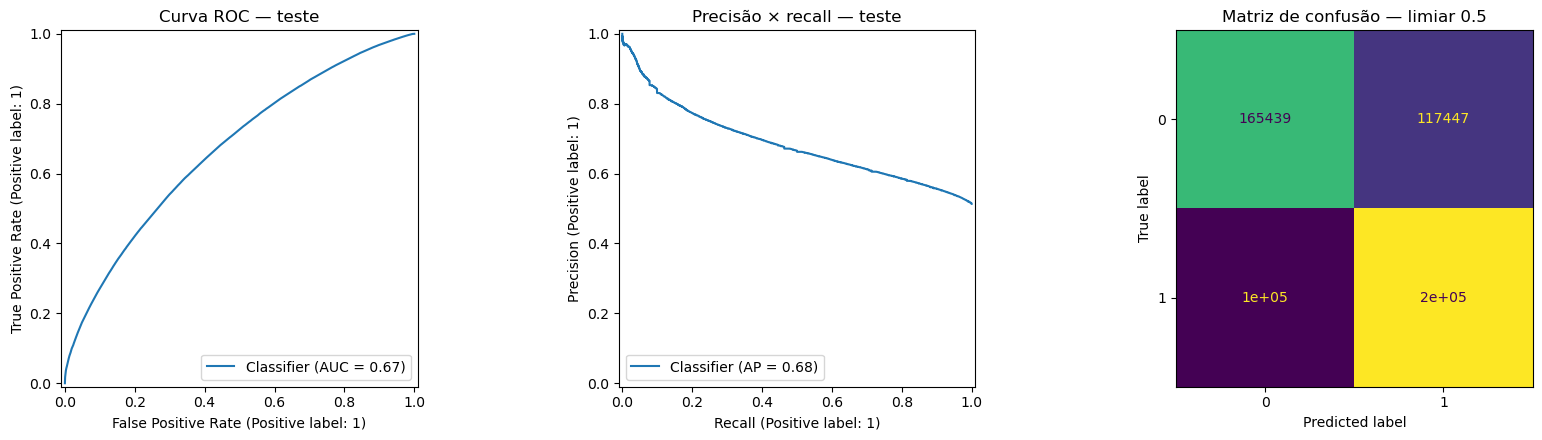

In [8]:
inicio = time.perf_counter()
score_test = modelo.predict_proba(X_test)[:, 1]
pred_test = np.asarray(score_test >= LIMIAR_CLASSIFICACAO, dtype=np.int8)
tempo_inferencia = time.perf_counter() - inicio

metricas_teste = calcular_metricas(y_test, pred_test, score_test)
display(pl.DataFrame([{k: v for k, v in metricas_teste.items() if k != "matriz_confusao"}]))
print("Matriz de confusão:", metricas_teste["matriz_confusao"])
print("Tempo de inferência (s):", tempo_inferencia)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
RocCurveDisplay.from_predictions(y_test, score_test, ax=axes[0])
axes[0].set_title("Curva ROC — teste")
PrecisionRecallDisplay.from_predictions(y_test, score_test, ax=axes[1])
axes[1].set_title("Precisão × recall — teste")
ConfusionMatrixDisplay.from_predictions(y_test, pred_test, ax=axes[2], colorbar=False)
axes[2].set_title(f"Matriz de confusão — limiar {LIMIAR_CLASSIFICACAO}")
plt.tight_layout()
salvar_figura_eda(plt.gcf(), "avaliacao_final_curvas_e_matriz.png"); plt.show()


## 6. Calibração das probabilidades


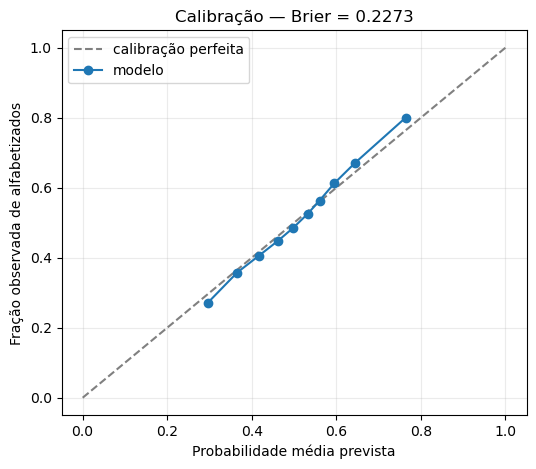

In [9]:
frac_pos, prob_media = calibration_curve(y_test, score_test, n_bins=10, strategy="quantile")
plt.figure(figsize=(6, 5))
plt.plot([0, 1], [0, 1], "--", color="gray", label="calibração perfeita")
plt.plot(prob_media, frac_pos, marker="o", label="modelo")
plt.xlabel("Probabilidade média prevista")
plt.ylabel("Fração observada de alfabetizados")
plt.title(f"Calibração — Brier = {metricas_teste['brier_score']:.4f}")
plt.legend()
plt.grid(alpha=0.25)
salvar_figura_eda(plt.gcf(), "avaliacao_final_calibracao.png"); plt.show()


## 7. Incerteza das métricas


In [10]:
rng = np.random.default_rng(SEED)
n_boot = tamanho_por_fracao(len(y_test), FRACAO_BOOTSTRAP)
base_idx = rng.choice(len(y_test), size=n_boot, replace=False)
y_boot_base = y_test[base_idx]
s_boot_base = score_test[base_idx]
p_boot_base = pred_test[base_idx]

amostras_metricas = []
for _ in range(REPETICOES_BOOTSTRAP):
    idx = rng.integers(0, n_boot, size=n_boot)
    yt, st, pt = y_boot_base[idx], s_boot_base[idx], p_boot_base[idx]
    if np.unique(yt).size < 2:
        continue
    amostras_metricas.append({
        "roc_auc": roc_auc_score(yt, st),
        "average_precision": average_precision_score(yt, st),
        "balanced_accuracy": balanced_accuracy_score(yt, pt),
        "f1": f1_score(yt, pt, zero_division=0),
    })

bootstrap = pl.DataFrame(amostras_metricas)
intervalos_95 = {
    coluna: {
        "inferior": float(bootstrap[coluna].quantile(0.025)),
        "superior": float(bootstrap[coluna].quantile(0.975)),
    }
    for coluna in bootstrap.columns
}
display(pl.DataFrame([{"metrica": k, **v} for k, v in intervalos_95.items()]))


metrica,inferior,superior
str,f64,f64
"""roc_auc""",0.667344,0.673679
"""average_precision""",0.681738,0.690173
"""balanced_accuracy""",0.616726,0.621786
"""f1""",0.636877,0.64306


## 8. Importância das variáveis


[cuml.accel] `RandomForestClassifier.predict_proba` ran on GPU
[cuml.accel] `RandomForestClassifier.predict_proba` ran on GPU
[cuml.accel] `RandomForestClassifier.predict_proba` ran on GPU
[cuml.accel] `RandomForestClassifier.predict_proba` ran on GPU
[cuml.accel] `RandomForestClassifier.predict_proba` ran on GPU
[cuml.accel] `RandomForestClassifier.predict_proba` ran on GPU
[cuml.accel] `RandomForestClassifier.predict_proba` ran on GPU
[cuml.accel] `RandomForestClassifier.predict_proba` ran on GPU
[cuml.accel] `RandomForestClassifier.predict_proba` ran on GPU
[cuml.accel] `RandomForestClassifier.predict_proba` ran on GPU
[cuml.accel] `RandomForestClassifier.predict_proba` ran on GPU
[cuml.accel] `RandomForestClassifier.predict_proba` ran on GPU
[cuml.accel] `RandomForestClassifier.predict_proba` ran on GPU
[cuml.accel] `RandomForestClassifier.predict_proba` ran on GPU
[cuml.accel] `RandomForestClassifier.predict_proba` ran on GPU
[cuml.accel] `RandomForestClassifier.predict_proba` ran

feature,importancia_media,importancia_desvio
str,f64,f64
"""sigla_uf""",0.081454,0.001723
"""valor_bolsa_familia__signed_lo…",0.013114,0.000664
"""media_inse""",0.008716,0.000608
"""rede""",0.007759,0.000488
"""in_laboratorio_informatica""",0.00525,0.000376
…,…,…
"""ano_referencia""",0.003185,0.000703
"""in_esgoto_rede_publica""",0.003007,0.000197
"""in_banda_larga""",0.001596,0.000069


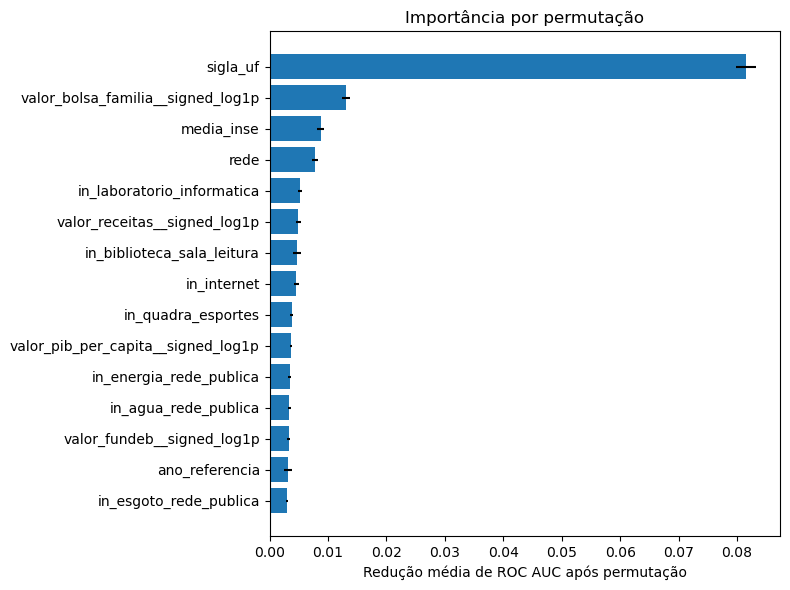

In [11]:
rng = np.random.default_rng(SEED)
n_interpretacao = tamanho_por_fracao(len(y_test), FRACAO_INTERPRETACAO)
idx_interpretacao = rng.choice(len(y_test), size=n_interpretacao, replace=False)
# No Polars, explicitar as duas dimensoes evita que a lista seja interpretada como colunas.
X_interpretacao = X_test[idx_interpretacao.tolist(), :]
y_interpretacao = y_test[idx_interpretacao]

# A rotina nativa do scikit-learn converte o Polars internamente e perde os
# nomes exigidos pelo ColumnTransformer. A implementação abaixo preserva
# o pl.DataFrame e calcula a mesma redução de ROC AUC por permutação.
score_referencia = roc_auc_score(
    y_interpretacao, modelo.predict_proba(X_interpretacao)[:, 1]
)
reducoes_auc = np.empty((len(FEATURES), REPETICOES_PERMUTACAO), dtype=float)

for indice_feature, feature in enumerate(FEATURES):
    valores_originais = X_interpretacao[feature].to_list()
    dtype_feature = X_interpretacao.schema[feature]
    for repeticao in range(REPETICOES_PERMUTACAO):
        ordem = rng.permutation(len(valores_originais))
        valores_permutados = [valores_originais[i] for i in ordem]
        X_permutado = X_interpretacao.with_columns(
            pl.Series(feature, valores_permutados, dtype=dtype_feature)
        )
        score_permutado = roc_auc_score(
            y_interpretacao, modelo.predict_proba(X_permutado)[:, 1]
        )
        reducoes_auc[indice_feature, repeticao] = score_referencia - score_permutado
importancias = (
    pl.DataFrame({
        "feature": FEATURES,
        "importancia_media": reducoes_auc.mean(axis=1),
        "importancia_desvio": reducoes_auc.std(axis=1),
    })
    .sort("importancia_media", descending=True)
)
display(importancias)

top = importancias.head(15).sort("importancia_media")
plt.figure(figsize=(8, 6))
plt.barh(top["feature"], top["importancia_media"], xerr=top["importancia_desvio"])
plt.xlabel("Redução média de ROC AUC após permutação")
plt.title("Importância por permutação")
plt.tight_layout()
salvar_figura_eda(plt.gcf(), "avaliacao_final_importancia_permutacao.png"); plt.show()


### 8.1 Leitura responsável da variável `sigla_uf`

`sigla_uf` resume diferenças territoriais acumuladas — financiamento, oferta educacional, infraestrutura, composição socioeconômica e políticas públicas. Ela é útil como **proxy preditiva**, mas não constitui causa isolada. A importância por permutação abaixo mede quanto o desempenho cai quando a informação de UF é embaralhada; não mede o efeito causal de pertencer a uma UF.


In [12]:
diagnostico_uf = (
    importancias
    .filter(pl.col("feature") == "sigla_uf")
    .with_columns(
        pl.lit("permutação no teste final; interpretação associativa").alias("metodo"),
        pl.lit("proxy territorial; não interpretar como causalidade").alias("advertencia"),
    )
)
display(diagnostico_uf)

if diagnostico_uf.height == 1:
    queda_auc_uf = diagnostico_uf["importancia_media"].item()
    print(f"Ao embaralhar UF, a queda média de ROC AUC foi {queda_auc_uf:.4f}.")
print("sigla_uf agrega diferenças entre políticas estaduais, investimento público, infraestrutura, contexto socioeconômico e desigualdades regionais.")
print("Ela é um proxy territorial: sua importância é preditiva e não identifica efeito causal da localização.")
print("sigla_uf agrega diferenças entre políticas estaduais, investimento público, infraestrutura, contexto socioeconômico e desigualdades regionais.")
print("Ela é um proxy territorial: sua importância é preditiva e não identifica efeito causal da localização.")
print("sigla_uf agrega diferenças entre políticas estaduais, investimento público, infraestrutura, contexto socioeconômico e desigualdades regionais.")
print("Ela é um proxy territorial: sua importância é preditiva e não identifica efeito causal da localização.")
print("A análise por UF deve ser lida em conjunto com cobertura, rede e tamanho amostral.")


feature,importancia_media,importancia_desvio,metodo,advertencia
str,f64,f64,str,str
"""sigla_uf""",0.081454,0.001723,"""permutação no teste final; int…","""proxy territorial; não interpr…"


Ao embaralhar UF, a queda média de ROC AUC foi 0.0815.
sigla_uf agrega diferenças entre políticas estaduais, investimento público, infraestrutura, contexto socioeconômico e desigualdades regionais.
Ela é um proxy territorial: sua importância é preditiva e não identifica efeito causal da localização.
sigla_uf agrega diferenças entre políticas estaduais, investimento público, infraestrutura, contexto socioeconômico e desigualdades regionais.
Ela é um proxy territorial: sua importância é preditiva e não identifica efeito causal da localização.
sigla_uf agrega diferenças entre políticas estaduais, investimento público, infraestrutura, contexto socioeconômico e desigualdades regionais.
Ela é um proxy territorial: sua importância é preditiva e não identifica efeito causal da localização.
A análise por UF deve ser lida em conjunto com cobertura, rede e tamanho amostral.


## 10.1 Análise de sensibilidade — modelo com e sem `sigla_uf`

Esta análise mede quanto o desempenho preditivo depende do proxy territorial. O Random Forest é repetido com os mesmos hiperparâmetros congelados, removendo somente `sigla_uf`. A comparação é pós-seleção e descritiva: não altera o algoritmo, os hiperparâmetros, o limiar ou o modelo oficial após observar o teste. Diferenças não devem ser interpretadas como efeito causal da UF.


In [13]:
FEATURES_SEM_UF = [feature for feature in FEATURES if feature != "sigla_uf"]
CATEGORICAS_SEM_UF = [feature for feature in ["rede"] if feature in FEATURES_SEM_UF]
NUMERICAS_SEM_UF = [feature for feature in FEATURES_SEM_UF if feature not in CATEGORICAS_SEM_UF]
INDICES_CATEGORICAS_SEM_UF = [FEATURES_SEM_UF.index(feature) for feature in CATEGORICAS_SEM_UF]
INDICES_NUMERICAS_SEM_UF = [FEATURES_SEM_UF.index(feature) for feature in NUMERICAS_SEM_UF]

categorico_sem_uf = Pipeline([
    ("imputer", SimpleImputer(strategy=IMPUTACAO_CATEGORICA_GLOBAL)),
    ("encoder", OneHotEncoder(
        handle_unknown=ONE_HOT_DESCONHECIDO_GLOBAL,
        sparse_output=ONE_HOT_SPARSO_GLOBAL,
        dtype=np.float32,
    )),
])
numerico_sem_uf = Pipeline([
    ("imputer", SimpleImputer(strategy=IMPUTACAO_NUMERICA_GLOBAL)),
])
preprocessador_sem_uf = ColumnTransformer(
    [
        ("categoricas", categorico_sem_uf, INDICES_CATEGORICAS_SEM_UF),
        ("numericas", numerico_sem_uf, INDICES_NUMERICAS_SEM_UF),
    ],
    sparse_threshold=SPARSE_THRESHOLD_GLOBAL,
)

estimador_sem_uf = RandomForestClassifier(random_state=SEED, n_jobs=N_JOBS_MODELAGEM_GLOBAL)
estimador_sem_uf.set_params(**parametros)
modelo_sem_uf = Pipeline([
    ("preprocessor", preprocessador_sem_uf),
    ("model", estimador_sem_uf),
])

X_dev_sem_uf = X_dev.select(FEATURES_SEM_UF)
X_test_sem_uf = X_test.select(FEATURES_SEM_UF)
modelo_sem_uf.fit(X_dev_sem_uf, y_dev)
validar_backend_modelo(modelo_sem_uf)
pred_test_sem_uf = np.asarray(modelo_sem_uf.predict(X_test_sem_uf))
score_test_sem_uf = pontuacao(modelo_sem_uf, X_test_sem_uf)
metricas_teste_sem_uf = calcular_metricas(y_test, pred_test_sem_uf, score_test_sem_uf)

metricas_sensibilidade = ["roc_auc", "average_precision", "balanced_accuracy", "f1"]
sensibilidade_uf = pl.DataFrame([
    {
        "metrica": metrica,
        "com_sigla_uf": metricas_teste[metrica],
        "sem_sigla_uf": metricas_teste_sem_uf[metrica],
        "diferenca_com_menos_sem": metricas_teste[metrica] - metricas_teste_sem_uf[metrica],
    }
    for metrica in metricas_sensibilidade
])
RESULTADOS_TABELAS_DIR.mkdir(parents=True, exist_ok=True)
sensibilidade_uf.write_csv(
    RESULTADOS_TABELAS_DIR / "18_sensibilidade_sigla_uf.csv"
)
display(sensibilidade_uf)
print("Análise pós-seleção: estes resultados não serão usados para novo tuning ou troca do modelo oficial.")


[cuml.accel] `RandomForestClassifier.fit` ran on GPU
Backend validado — RandomForestClassifier: GPU
[cuml.accel] `RandomForestClassifier.predict` ran on GPU
[cuml.accel] `RandomForestClassifier.predict_proba` ran on GPU


metrica,com_sigla_uf,sem_sigla_uf,diferenca_com_menos_sem
str,f64,f64,f64
"""roc_auc""",0.670483,0.675669,-0.005187
"""average_precision""",0.684097,0.691022,-0.006925
"""balanced_accuracy""",0.619615,0.623244,-0.003629
"""f1""",0.639195,0.636279,0.002916


Análise pós-seleção: estes resultados não serão usados para novo tuning ou troca do modelo oficial.


## 9. Estabilidade por ano, rede e UF; agregação municipal


In [14]:
avaliacao = teste.select(["id_municipio", "sigla_uf", "rede", "ano_referencia", TARGET]).with_columns(
    pl.Series("probabilidade", score_test), pl.Series("predicao", pred_test)
)

def avaliar_recortes(frame: pl.DataFrame, coluna: str, minimo: int = 500) -> pl.DataFrame:
    linhas = []
    for grupo in frame.partition_by(coluna, as_dict=False, maintain_order=True):
        if grupo.height < minimo or grupo[TARGET].n_unique() < 2:
            continue
        y_grupo = grupo[TARGET].to_numpy()
        pred_grupo = grupo["predicao"].to_numpy()
        score_grupo = grupo["probabilidade"].to_numpy()
        tn, fp, fn, tp = confusion_matrix(y_grupo, pred_grupo, labels=[0, 1]).ravel()
        taxa_observada = float(y_grupo.mean())
        probabilidade_media = float(score_grupo.mean())
        linhas.append({
            coluna: grupo[coluna][0], "registros": grupo.height,
            "taxa_observada": taxa_observada,
            "probabilidade_media": probabilidade_media,
            "erro_calibracao_medio": probabilidade_media - taxa_observada,
            "taxa_predita_positiva": float(pred_grupo.mean()),
            "sensibilidade": tp / (tp + fn) if (tp + fn) else None,
            "especificidade": tn / (tn + fp) if (tn + fp) else None,
            "roc_auc": roc_auc_score(y_grupo, score_grupo),
            "balanced_accuracy": balanced_accuracy_score(y_grupo, pred_grupo),
            "f1": f1_score(y_grupo, pred_grupo, zero_division=0),
            "alerta_limiar": "predição de uma classe" if np.unique(pred_grupo).size < 2 else "",
        })
    return pl.DataFrame(linhas)

recortes = {nome: avaliar_recortes(avaliacao, coluna) for nome, coluna in {
    "ano": "ano_referencia", "rede": "rede", "uf": "sigla_uf"
}.items()}
for nome, tabela in recortes.items():
    print("\nRecorte:", nome); display(tabela)
    if not tabela.is_empty():
        alertas = tabela.filter(pl.col("alerta_limiar") != "")
        if not alertas.is_empty():
            print(f"Atenção: {alertas.height} recorte(s) com predição de uma única classe no limiar global {LIMIAR_CLASSIFICACAO}.")

municipios = avaliacao.group_by(["ano_referencia", "id_municipio", "sigla_uf", "rede"]).agg(
    pl.len().alias("registros"),
    pl.col(TARGET).mean().alias("taxa_alfabetizacao_observada"),
    pl.col("probabilidade").mean().alias("probabilidade_media"),
)
display(municipios.head())



Recorte: ano


ano_referencia,registros,taxa_observada,probabilidade_media,erro_calibracao_medio,taxa_predita_positiva,sensibilidade,especificidade,roc_auc,balanced_accuracy,f1,alerta_limiar
i64,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str
2024,318824,0.523552,0.518623,-0.004929,0.560052,0.674672,0.565901,0.670886,0.620287,0.651947,""""""
2023,262767,0.501524,0.506193,0.004669,0.511339,0.628733,0.606773,0.669005,0.617753,0.622641,""""""



Recorte: rede


rede,registros,taxa_observada,probabilidade_media,erro_calibracao_medio,taxa_predita_positiva,sensibilidade,especificidade,roc_auc,balanced_accuracy,f1,alerta_limiar
str,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str
"""2""",65599,0.529871,0.522121,-0.00775,0.588957,0.683909,0.518061,0.645759,0.600985,0.647791,""""""
"""3""",515992,0.511531,0.511848,0.000317,0.53157,0.650519,0.592995,0.673115,0.621757,0.638022,""""""



Recorte: uf


sigla_uf,registros,taxa_observada,probabilidade_media,erro_calibracao_medio,taxa_predita_positiva,sensibilidade,especificidade,roc_auc,balanced_accuracy,f1,alerta_limiar
str,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str
"""AC""",1898,0.443625,0.432375,-0.01125,0.050053,0.071259,0.966856,0.589067,0.519057,0.128068,""""""
"""AL""",10554,0.441349,0.439999,-0.00135,0.155107,0.264062,0.93097,0.644353,0.597516,0.390786,""""""
"""AM""",18302,0.404765,0.402807,-0.001957,0.086165,0.132559,0.945383,0.601315,0.538971,0.218587,""""""
"""AP""",3707,0.40491,0.401295,-0.003615,0.058808,0.097935,0.967815,0.604023,0.532875,0.17103,""""""
"""BA""",38444,0.319582,0.321147,0.001565,0.003225,0.00643,0.99828,0.595232,0.502355,0.012732,""""""
…,…,…,…,…,…,…,…,…,…,…,…
"""RS""",34544,0.457214,0.462864,0.00565,0.399925,0.514119,0.696267,0.651248,0.605193,0.548482,""""""
"""SC""",30283,0.469702,0.474074,0.004372,0.413103,0.506116,0.669282,0.632902,0.587699,0.538565,""""""
"""SE""",5649,0.345017,0.344387,-0.00063,0.06957,0.116983,0.955405,0.612811,0.536194,0.194705,""""""


Atenção: 3 recorte(s) com predição de uma única classe no limiar global 0.5.


ano_referencia,id_municipio,sigla_uf,rede,registros,taxa_alfabetizacao_observada,probabilidade_media
i64,i64,str,str,u32,f64,f32
2023,2408102,"""RN""","""2""",214,0.285047,0.322513
2024,3500105,"""SP""","""3""",35,0.685714,0.55853
2023,3111309,"""MG""","""3""",16,0.5625,0.598865
2023,2927408,"""BA""","""3""",2438,0.327728,0.3297
2024,1200302,"""AC""","""3""",35,0.4,0.41984


## 10. Exportação dos artefatos deste modelo


In [15]:
MODEL_DIR = MODELOS_DIR / "random_forest"
METRICAS_FINAIS_DIR = RESULTADOS_METRICAS_DIR / "fase_7"
ANALITICOS_FINAIS_DIR = DADOS_ANALITICOS_DIR / "avaliacao_independente"
for diretorio in (MODEL_DIR, METRICAS_FINAIS_DIR, ANALITICOS_FINAIS_DIR):
    diretorio.mkdir(parents=True, exist_ok=True)

joblib.dump(modelo, MODEL_DIR / "modelo_pipeline.joblib")
importancias.write_csv(RESULTADOS_TABELAS_DIR / "importancia_permutacao.csv")
municipios.write_parquet(ANALITICOS_FINAIS_DIR / "predicoes_agregadas_municipio.parquet")
for nome, tabela in recortes.items():
    tabela.write_csv(RESULTADOS_TABELAS_DIR / f"metricas_por_{nome}.csv")

resultado = {
    "schema_resultado": 1,
    "modelo": "Random Forest",
    "modo": "avaliacao_final_independente",
    "hipotese": "modelo tratado como único candidato selecionado",
    "manifesto": MANIFEST_PATH.relative_to(PROJECT_ROOT).as_posix(),
    "features": FEATURES,
    "parametros": parametros,
    "limiar_classificacao": LIMIAR_CLASSIFICACAO,
    "registros_desenvolvimento": int(len(y_dev)),
    "registros_teste": int(len(y_test)),
    "metricas_teste": metricas_teste,
    "intervalos_95_bootstrap": intervalos_95,
    "tempo_treino_segundos": float(tempo_treino),
    "tempo_inferencia_segundos": float(tempo_inferencia),
    "avisos_treinamento": [str(a.message) for a in avisos_treino],
    "ambiente": {
        "python": platform.python_version(),
        "scikit_learn": sklearn.__version__,
        "polars": pl.__version__,
    },
    "ressalvas": [
        "id_escola e chave_escola_ano não foram utilizadas como features.",
        "A chave de escola é anônima e anual; não identifica a unidade real.",
        "São Paulo possui registros somente em 2024.",
        "Resultados por município, UF e rede são associações preditivas, não efeitos causais.",
        "O teste não deve ser reutilizado para ajustar features, hiperparâmetros ou limiar.",
        "Recortes com predição de uma única classe no limiar global indicam limitação de transportabilidade, não erro de execução.",
        "A importância de sigla_uf representa sinal territorial e possível uso de proxy geográfica; não implica causalidade.",
    ],
}
(METRICAS_FINAIS_DIR / "resultado_final.json").write_text(
    json.dumps(resultado, ensure_ascii=False, indent=2), encoding="utf-8"
)
print("Modelo:", MODEL_DIR)
print("Métricas:", METRICAS_FINAIS_DIR)
print("Dados analíticos:", ANALITICOS_FINAIS_DIR)


Modelo: /workspace/modelos/random_forest
Métricas: /workspace/resultados/metricas/fase_7
Dados analíticos: /workspace/dados/dados_analiticos/avaliacao_independente


<a id="inteligencia-analitica"></a>

# Camada final de inteligência analítica

Esta seção responde às perguntas norteadoras usando exclusivamente o modelo já congelado e as previsões da avaliação independente. Nenhuma análise abaixo retorna ao treinamento, altera features, hiperparâmetros ou limiar. Os resultados são associações descritivas e preditivas, não efeitos causais.


In [16]:
from datetime import datetime, timezone
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
from scipy.stats import spearmanr
from IPython.display import Markdown

ANALISE_DIR = RESULTADOS_RELATORIOS_DIR
FIGURAS_DIR = RESULTADOS_FIGURAS_DIR
TABELAS_DIR = RESULTADOS_TABELAS_DIR
for diretorio in (ANALISE_DIR, FIGURAS_DIR, TABELAS_DIR):
    diretorio.mkdir(parents=True, exist_ok=True)

LIMITES_RISCO_META = {"alto": 0.10, "moderado": 0.05, "atencao": 0.00}

def salvar_figura(fig, nome):
    caminho = FIGURAS_DIR / nome
    fig.savefig(caminho, dpi=180, bbox_inches="tight")
    return caminho

def resumo_faixas(frame: pl.DataFrame, feature: str, grupos: int = 5, por_ano: bool = False) -> pl.DataFrame:
    if feature not in frame.columns:
        return pl.DataFrame()
    base = frame.select([feature, TARGET, "probabilidade", "ano_referencia", "rede"]).with_columns(
        pl.col(feature).cast(pl.Float64, strict=False)
    ).drop_nulls([feature])
    if base.is_empty() or base[feature].n_unique() < 2:
        return pl.DataFrame()
    base = base.with_columns(pl.col(feature).bin_quantiles(grupos, labels=False).cast(pl.String).alias("faixa"))
    chaves = (["ano_referencia"] if por_ano else []) + ["faixa"]
    return base.group_by(chaves, maintain_order=True).agg(
        pl.len().alias("registros"), pl.col(feature).mean().alias("feature_media"),
        pl.col(TARGET).mean().alias("taxa_observada"),
        pl.col("probabilidade").mean().alias("probabilidade_media"),
    ).sort(chaves)

colunas_contexto = list(dict.fromkeys(["id_municipio", "sigla_uf", "rede", "ano_referencia", TARGET, *FEATURES]))
avaliacao_contextual = teste.select(colunas_contexto).with_columns(
    pl.Series("probabilidade", score_test), pl.Series("predicao", pred_test)
)
print("Diretório da análise final:", ANALISE_DIR)


Diretório da análise final: /workspace/resultados/relatorios


## 11. Evidências visuais do modelo final

Os gráficos principais são recriados e persistidos para uso no relatório e no vídeo. A exportação não altera as métricas.


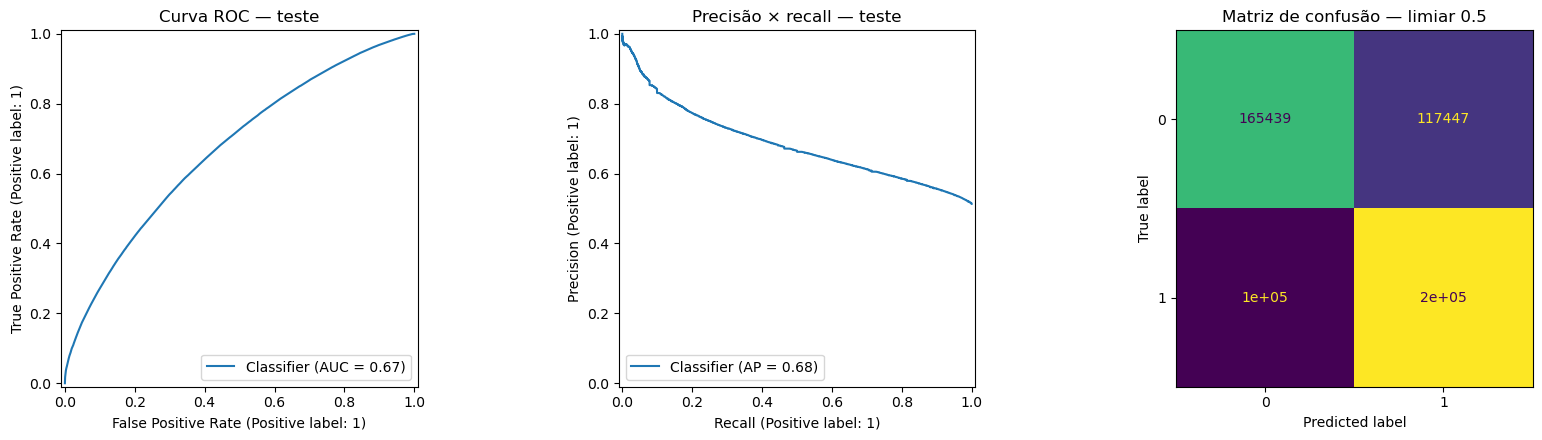

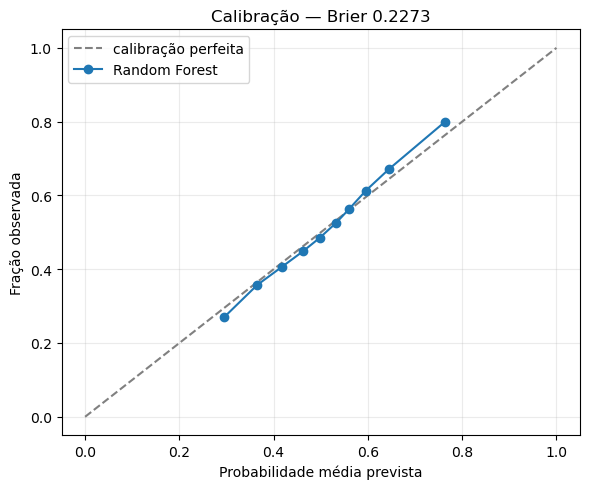

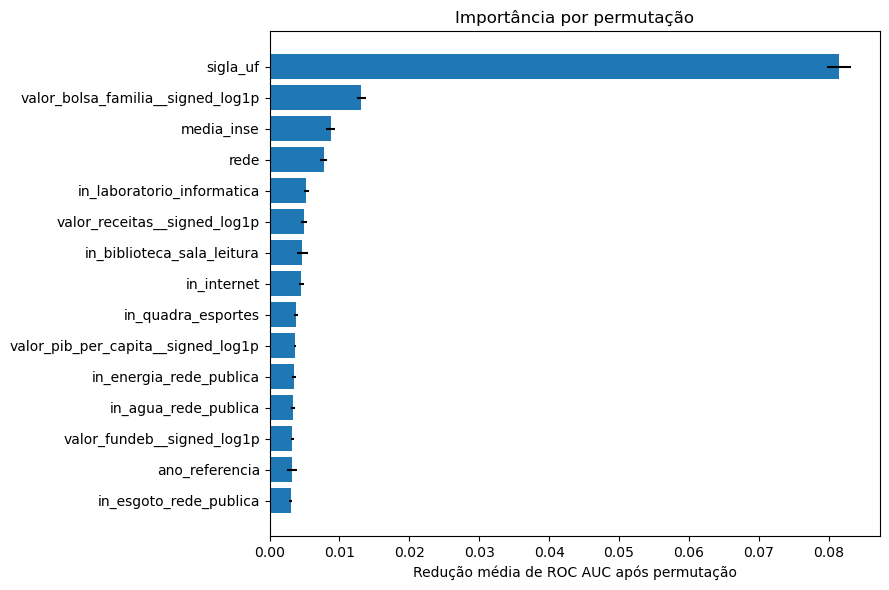

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
RocCurveDisplay.from_predictions(y_test, score_test, ax=axes[0])
axes[0].set_title("Curva ROC — teste")
PrecisionRecallDisplay.from_predictions(y_test, score_test, ax=axes[1])
axes[1].set_title("Precisão × recall — teste")
ConfusionMatrixDisplay.from_predictions(y_test, pred_test, ax=axes[2], colorbar=False)
axes[2].set_title(f"Matriz de confusão — limiar {LIMIAR_CLASSIFICACAO}")
fig.tight_layout()
salvar_figura(fig, "01_metricas_classificacao.png")
plt.show()

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot([0, 1], [0, 1], "--", color="gray", label="calibração perfeita")
ax.plot(prob_media, frac_pos, marker="o", label="Random Forest")
ax.set(xlabel="Probabilidade média prevista", ylabel="Fração observada", title=f"Calibração — Brier {metricas_teste['brier_score']:.4f}")
ax.legend(); ax.grid(alpha=0.25); fig.tight_layout()
salvar_figura(fig, "02_calibracao.png")
plt.show()

top_plot = importancias.head(15).sort("importancia_media")
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top_plot["feature"], top_plot["importancia_media"], xerr=top_plot["importancia_desvio"])
ax.set(xlabel="Redução média de ROC AUC após permutação", title="Importância por permutação")
fig.tight_layout()
salvar_figura(fig, "03_importancia_permutacao.png")
plt.show()


## 12. Fatores contextuais associados

A importância por permutação mede perda de desempenho quando uma variável é embaralhada. Ela não informa causalidade e sua direção deve ser complementada pelas análises por faixa abaixo.


In [18]:
fatores_associados = importancias.with_columns(
    pl.lit("importância preditiva por permutação").alias("tipo_evidencia"),
    pl.when(pl.col("importancia_media") > 0)
      .then(pl.lit("contribui para discriminação no conjunto avaliado"))
      .otherwise(pl.lit("sem ganho preditivo estável nesta análise")).alias("interpretacao"),
    pl.lit("associação contextual; não representa efeito causal individual").alias("limitacao"),
)
fatores_associados.write_csv(TABELAS_DIR / "01_fatores_associados.csv")
display(fatores_associados.head(15))


feature,importancia_media,importancia_desvio,tipo_evidencia,interpretacao,limitacao
str,f64,f64,str,str,str
"""sigla_uf""",0.081454,0.001723,"""importância preditiva por perm…","""contribui para discriminação n…","""associação contextual; não rep…"
"""valor_bolsa_familia__signed_lo…",0.013114,0.000664,"""importância preditiva por perm…","""contribui para discriminação n…","""associação contextual; não rep…"
"""media_inse""",0.008716,0.000608,"""importância preditiva por perm…","""contribui para discriminação n…","""associação contextual; não rep…"
"""rede""",0.007759,0.000488,"""importância preditiva por perm…","""contribui para discriminação n…","""associação contextual; não rep…"
"""in_laboratorio_informatica""",0.00525,0.000376,"""importância preditiva por perm…","""contribui para discriminação n…","""associação contextual; não rep…"
…,…,…,…,…,…
"""in_energia_rede_publica""",0.003443,0.000295,"""importância preditiva por perm…","""contribui para discriminação n…","""associação contextual; não rep…"
"""in_agua_rede_publica""",0.003356,0.000264,"""importância preditiva por perm…","""contribui para discriminação n…","""associação contextual; não rep…"
"""valor_fundeb__signed_log1p""",0.003245,0.000244,"""importância preditiva por perm…","""contribui para discriminação n…","""associação contextual; não rep…"


## 13. Infraestrutura municipal

As variáveis representam proporções municipais de escolas com cada recurso. Elas não identificam a infraestrutura da escola frequentada por um aluno específico.


feature,ano_referencia,faixa,registros,feature_media,taxa_observada,probabilidade_media
str,i64,str,u32,f64,f64,f32
"""in_biblioteca_sala_leitura""",2023,"""0""",53105,0.267534,0.449656,0.455602
"""in_biblioteca_sala_leitura""",2023,"""1""",39800,0.501187,0.494824,0.501307
"""in_biblioteca_sala_leitura""",2023,"""2""",53998,0.625832,0.509408,0.515475
"""in_biblioteca_sala_leitura""",2023,"""3""",51537,0.712559,0.51074,0.511298
"""in_biblioteca_sala_leitura""",2023,"""4""",64327,0.82958,0.534488,0.5391
…,…,…,…,…,…,…
"""in_laboratorio_informatica""",2024,"""0""",55127,0.102677,0.483066,0.477027
"""in_laboratorio_informatica""",2024,"""1""",63649,0.256533,0.514839,0.509716
"""in_laboratorio_informatica""",2024,"""2""",71166,0.353274,0.496866,0.496048


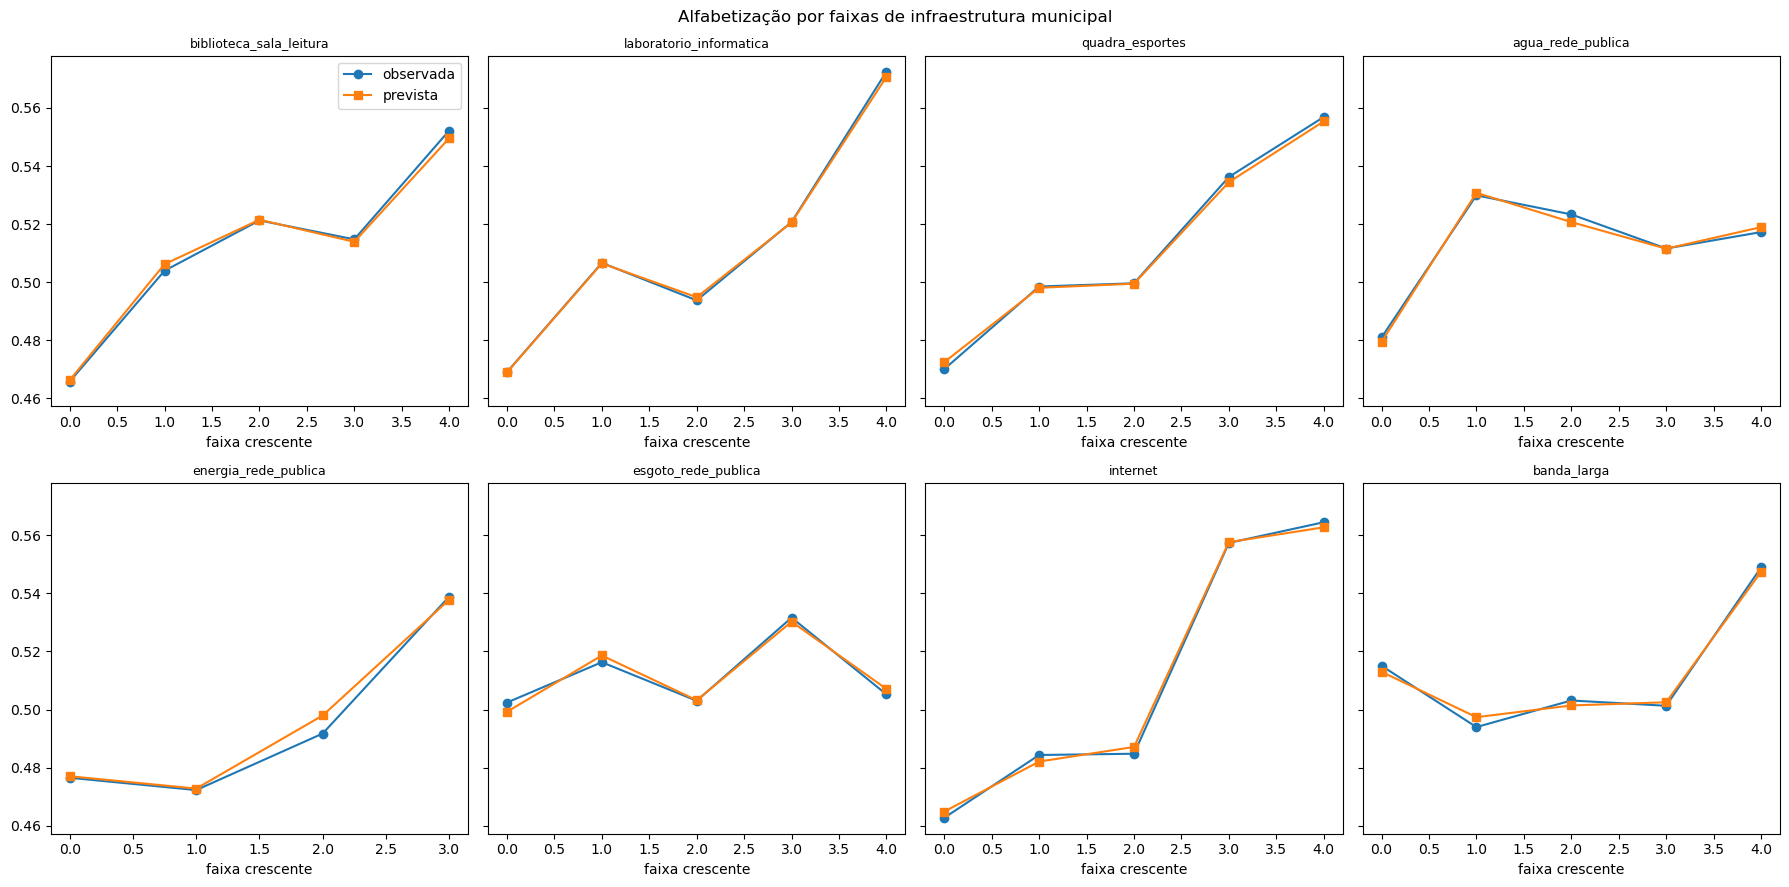

In [19]:
FEATURES_INFRA = [
    "in_biblioteca_sala_leitura", "in_laboratorio_informatica", "in_quadra_esportes",
    "in_agua_rede_publica", "in_energia_rede_publica", "in_esgoto_rede_publica",
    "in_internet", "in_banda_larga",
]
infra_tabelas = []
for feature in FEATURES_INFRA:
    tabela = resumo_faixas(avaliacao_contextual, feature, grupos=5, por_ano=True)
    if not tabela.is_empty():
        infra_tabelas.append(tabela.with_columns(pl.lit(feature).alias("feature")).select(["feature", *tabela.columns]))
infraestrutura = pl.concat(infra_tabelas, how="diagonal_relaxed") if infra_tabelas else pl.DataFrame()
infraestrutura.write_csv(TABELAS_DIR / "02_infraestrutura_por_faixa_ano.csv")
display(infraestrutura.head(20))

if not infraestrutura.is_empty():
    resumo_infra = infraestrutura.group_by(["feature", "faixa"]).agg(
        pl.col("feature_media").mean(), pl.col("taxa_observada").mean(), pl.col("probabilidade_media").mean()
    ).sort(["feature", "faixa"])
    fig, axes = plt.subplots(2, 4, figsize=(18, 9), sharey=True)
    for ax, feature in zip(axes.ravel(), FEATURES_INFRA):
        sub = resumo_infra.filter(pl.col("feature") == feature)
        ax.plot(range(sub.height), sub["taxa_observada"].to_numpy(), marker="o", label="observada")
        ax.plot(range(sub.height), sub["probabilidade_media"].to_numpy(), marker="s", label="prevista")
        ax.set_title(feature.replace("in_", ""), fontsize=9); ax.set_xlabel("faixa crescente")
    axes[0, 0].legend(); fig.suptitle("Alfabetização por faixas de infraestrutura municipal")
    fig.tight_layout(); salvar_figura(fig, "04_infraestrutura_faixas.png"); plt.show()


## 14. INSE municipal

`media_inse` é uma medida contextual municipal de 2023. A análise separa os resultados de 2023 e 2024 e não a interpreta como característica individual do aluno.


ano_referencia,faixa,registros,feature_media,taxa_observada,probabilidade_media
i64,str,u32,f64,f64,f32
2023,"""0""",59972,4.285343,0.486194,0.494968
2023,"""1""",60244,4.636339,0.454004,0.457364
2023,"""2""",54973,4.983847,0.500646,0.508365
2023,"""3""",43307,5.229293,0.528875,0.540434
2023,"""4""",44271,5.477584,0.561293,0.551654
2024,"""0""",55282,4.284824,0.513006,0.508842
2024,"""1""",57136,4.643132,0.482288,0.473709
2024,"""2""",55267,4.987907,0.547813,0.536995
2024,"""3""",79047,5.207266,0.540375,0.535318


ano_referencia,spearman_target,spearman_probabilidade,registros
i64,f64,f64,i64
2024,0.02403,0.173926,318824
2023,0.058576,0.28052,262767


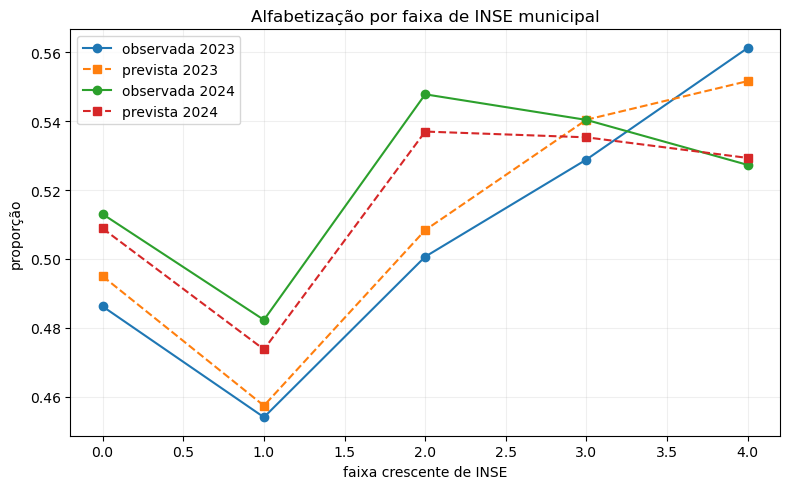

In [20]:
inse_faixas = resumo_faixas(avaliacao_contextual, "media_inse", grupos=5, por_ano=True)
inse_faixas.write_csv(TABELAS_DIR / "03_inse_por_faixa_ano.csv")
linhas_correlacao = []
for grupo in avaliacao_contextual.select(["ano_referencia", "media_inse", TARGET, "probabilidade"]).drop_nulls().partition_by("ano_referencia"):
    linhas_correlacao.append({
        "ano_referencia": grupo["ano_referencia"][0],
        "spearman_target": float(spearmanr(grupo["media_inse"].to_numpy(), grupo[TARGET].to_numpy()).statistic),
        "spearman_probabilidade": float(spearmanr(grupo["media_inse"].to_numpy(), grupo["probabilidade"].to_numpy()).statistic),
        "registros": grupo.height,
    })
correlacao_inse = pl.DataFrame(linhas_correlacao)
correlacao_inse.write_csv(TABELAS_DIR / "04_inse_correlacoes.csv")
display(inse_faixas, correlacao_inse)

fig, ax = plt.subplots(figsize=(8, 5))
for grupo in inse_faixas.partition_by("ano_referencia", maintain_order=True):
    ano = grupo["ano_referencia"][0]
    ax.plot(range(grupo.height), grupo["taxa_observada"].to_numpy(), marker="o", label=f"observada {ano}")
    ax.plot(range(grupo.height), grupo["probabilidade_media"].to_numpy(), marker="s", linestyle="--", label=f"prevista {ano}")
ax.set(xlabel="faixa crescente de INSE", ylabel="proporção", title="Alfabetização por faixa de INSE municipal")
ax.legend(); ax.grid(alpha=0.2); fig.tight_layout(); salvar_figura(fig, "05_inse_faixas.png"); plt.show()


## 15. Persistência municipal entre 2023 e 2024

A comparação utiliza somente municípios e redes presentes nos dois anos. Ela mede persistência de curto prazo; dois anos não constituem tendência histórica longa.


municipios_redes_comparaveis,spearman_observado_2023_2024,spearman_previsto_2023_2024
i64,f64,f64
5653,0.447454,0.893588


faixa_2023,faixa_2024,len,proporcao
str,str,u32,f64
"""alto""","""medio""",427,0.226645
"""baixo""","""alto""",354,0.186022
"""baixo""","""baixo""",1009,0.530215
"""alto""","""alto""",1189,0.631104
"""alto""","""baixo""",268,0.142251
"""medio""","""baixo""",470,0.251876
"""medio""","""alto""",589,0.315648
"""baixo""","""medio""",540,0.283762
"""medio""","""medio""",807,0.432476


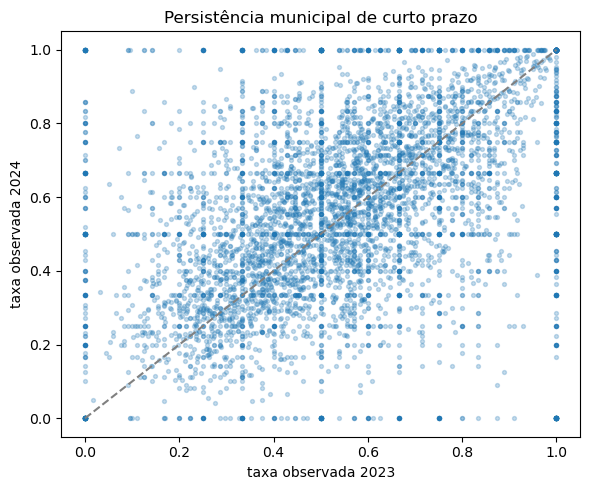

In [21]:
chaves_painel = ["id_municipio", "sigla_uf", "rede"]
metricas_painel = ["registros", "taxa_alfabetizacao_observada", "probabilidade_media"]
painel_2023 = municipios.filter(pl.col("ano_referencia") == 2023).select(chaves_painel + metricas_painel).rename(
    {c: f"{c}_2023" for c in metricas_painel}
)
painel_2024 = municipios.filter(pl.col("ano_referencia") == 2024).select(chaves_painel + metricas_painel).rename(
    {c: f"{c}_2024" for c in metricas_painel}
)
painel_comparavel = painel_2023.join(painel_2024, on=chaves_painel, how="inner").drop_nulls()
painel_comparavel = painel_comparavel.with_columns(
    (100 * (pl.col("taxa_alfabetizacao_observada_2024") - pl.col("taxa_alfabetizacao_observada_2023"))).alias("variacao_observada_pp"),
    (100 * (pl.col("probabilidade_media_2024") - pl.col("probabilidade_media_2023"))).alias("variacao_prevista_pp"),
)
q1, q2 = painel_comparavel["taxa_alfabetizacao_observada_2023"].quantile(1/3), painel_comparavel["taxa_alfabetizacao_observada_2023"].quantile(2/3)
def faixa_expr(coluna):
    return pl.when(pl.col(coluna) <= q1).then(pl.lit("baixo")).when(pl.col(coluna) <= q2).then(pl.lit("medio")).otherwise(pl.lit("alto"))
painel_comparavel = painel_comparavel.with_columns(
    faixa_expr("taxa_alfabetizacao_observada_2023").alias("faixa_2023"),
    faixa_expr("taxa_alfabetizacao_observada_2024").alias("faixa_2024"),
)
transicao = painel_comparavel.group_by(["faixa_2023", "faixa_2024"]).len().with_columns(
    (pl.col("len") / pl.col("len").sum().over("faixa_2023")).alias("proporcao")
)
persistencia = {
    "municipios_redes_comparaveis": painel_comparavel.height,
    "spearman_observado_2023_2024": float(spearmanr(painel_comparavel["taxa_alfabetizacao_observada_2023"].to_numpy(), painel_comparavel["taxa_alfabetizacao_observada_2024"].to_numpy()).statistic),
    "spearman_previsto_2023_2024": float(spearmanr(painel_comparavel["probabilidade_media_2023"].to_numpy(), painel_comparavel["probabilidade_media_2024"].to_numpy()).statistic),
}
painel_comparavel.write_csv(TABELAS_DIR / "05_painel_municipal_2023_2024.csv")
transicao.write_csv(TABELAS_DIR / "06_transicao_faixas_2023_2024.csv")
display(pl.DataFrame([persistencia]), transicao)
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(painel_comparavel["taxa_alfabetizacao_observada_2023"].to_numpy(), painel_comparavel["taxa_alfabetizacao_observada_2024"].to_numpy(), s=8, alpha=0.25)
ax.plot([0, 1], [0, 1], "--", color="gray")
ax.set(xlabel="taxa observada 2023", ylabel="taxa observada 2024", title="Persistência municipal de curto prazo")
fig.tight_layout(); salvar_figura(fig, "06_persistencia_2023_2024.png"); plt.show()


## 16. Variáveis financeiras e porte municipal

As variáveis financeiras são analisadas como associações preditivas. Totais municipais podem capturar porte e não equivalem a gasto educacional por aluno.


feature,ano_referencia,faixa,registros,feature_media,taxa_observada,probabilidade_media
str,i64,str,u32,f64,f64,f32
"""valor_bolsa_familia__signed_lo…",2023,"""0""",58498,15.634377,0.568994,0.568827
"""valor_bolsa_familia__signed_lo…",2023,"""1""",57046,17.097563,0.512288,0.52205
"""valor_bolsa_familia__signed_lo…",2023,"""2""",55271,18.034162,0.49431,0.500703
"""valor_bolsa_familia__signed_lo…",2023,"""3""",45106,18.993717,0.467831,0.469238
"""valor_bolsa_familia__signed_lo…",2023,"""4""",46846,20.770401,0.445118,0.450732
…,…,…,…,…,…,…
"""valor_fundeb__signed_log1p""",2024,"""0""",59508,-21.88184,0.498101,0.492744
"""valor_fundeb__signed_log1p""",2024,"""1""",51301,8.258138,0.559034,0.551002
"""valor_fundeb__signed_log1p""",2024,"""2""",67329,18.799335,0.561422,0.553957


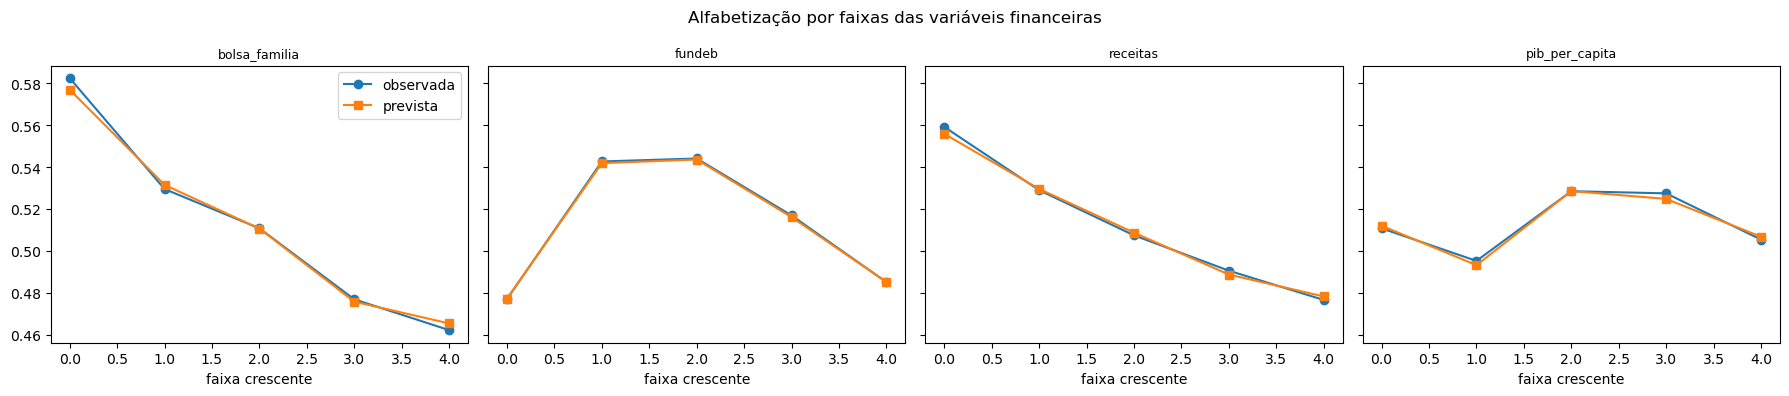

In [22]:
FEATURES_FINANCEIRAS = [
    "valor_bolsa_familia__signed_log1p", "valor_fundeb__signed_log1p",
    "valor_receitas__signed_log1p", "valor_pib_per_capita__signed_log1p",
]
financeiro_tabelas = []
for feature in FEATURES_FINANCEIRAS:
    tabela = resumo_faixas(avaliacao_contextual, feature, grupos=5, por_ano=True)
    if not tabela.is_empty():
        financeiro_tabelas.append(tabela.with_columns(pl.lit(feature).alias("feature")).select(["feature", *tabela.columns]))
financeiro = pl.concat(financeiro_tabelas, how="diagonal_relaxed") if financeiro_tabelas else pl.DataFrame()
financeiro.write_csv(TABELAS_DIR / "07_financas_por_faixa_ano.csv")
display(financeiro.head(20))
fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
for ax, feature in zip(axes, FEATURES_FINANCEIRAS):
    sub = financeiro.filter(pl.col("feature") == feature).group_by("faixa").agg(
        pl.col("taxa_observada").mean(), pl.col("probabilidade_media").mean()
    ).sort("faixa")
    ax.plot(range(sub.height), sub["taxa_observada"].to_numpy(), marker="o", label="observada")
    ax.plot(range(sub.height), sub["probabilidade_media"].to_numpy(), marker="s", label="prevista")
    ax.set_title(feature.replace("valor_", "").replace("__signed_log1p", ""), fontsize=9); ax.set_xlabel("faixa crescente")
axes[0].legend(); fig.suptitle("Alfabetização por faixas das variáveis financeiras")
fig.tight_layout(); salvar_figura(fig, "07_financas_faixas.png"); plt.show()


## 17. Perfis municipais por cluster

Os clusters são construídos somente com características contextuais. Taxa observada e probabilidade prevista são usadas depois para descrever os grupos, não para formá-los. O número de clusters é escolhido por silhouette entre alternativas previamente limitadas.


[cuml.accel] `KMeans.fit_predict` ran on GPU
[cuml.accel] `KMeans.fit_predict` ran on GPU
[cuml.accel] `KMeans.fit_predict` ran on GPU
[cuml.accel] `KMeans.fit_predict` ran on GPU
[cuml.accel] `KMeans.fit_predict` ran on GPU


k,silhouette,inercia
i64,f64,f64
2,0.234729,145246.867021
3,0.239884,132844.939996
4,0.238055,119158.283059
5,0.196988,106848.97972
6,0.200032,94684.292156


cluster,municipios_ano,taxa_observada,probabilidade_media,media_media_inse,media_valor_bolsa_familia__signed_log1p,media_valor_fundeb__signed_log1p,media_valor_receitas__signed_log1p,media_valor_pib_per_capita__signed_log1p,media_in_biblioteca_sala_leitura,media_in_laboratorio_informatica,media_in_quadra_esportes,media_in_agua_rede_publica,media_in_energia_rede_publica,media_in_esgoto_rede_publica,media_in_internet,media_in_banda_larga,media_cobertura_financeira_ausente,media_cobertura_inse_ausente
i32,u32,f64,f32,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
0,7255,0.597089,0.588593,5.185537,15.634121,14.94687,20.644875,10.657631,0.674692,0.435116,0.496007,0.886803,0.996185,0.580461,0.986261,0.86142,0.002619,0.0
1,5058,0.502714,0.501366,4.395372,16.757079,10.623436,20.371199,9.739427,0.376755,0.170189,0.212074,0.598757,0.964814,0.248292,0.84842,0.766286,0.006129,0.0
2,25,0.638583,0.648818,4.999194,13.878669,18.096998,19.987373,10.724394,0.727486,0.43499,0.483714,0.933333,0.992,0.622057,1.0,0.647048,0.0,1.0


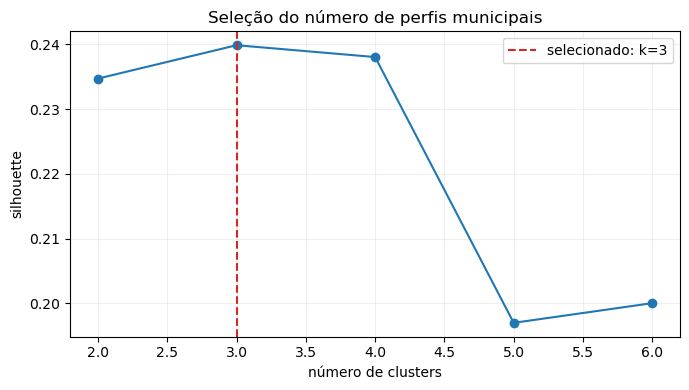

In [23]:
FEATURES_CLUSTER = [
    "media_inse", "valor_bolsa_familia__signed_log1p", "valor_fundeb__signed_log1p",
    "valor_receitas__signed_log1p", "valor_pib_per_capita__signed_log1p",
    *FEATURES_INFRA, "cobertura_financeira_ausente", "cobertura_inse_ausente",
]
municipios_contexto = avaliacao_contextual.group_by(["ano_referencia", "id_municipio", "sigla_uf", "rede"]).agg(
    *[pl.col(feature).mean().alias(feature) for feature in FEATURES_CLUSTER],
    pl.len().alias("registros"), pl.col(TARGET).mean().alias("taxa_observada"),
    pl.col("probabilidade").mean().alias("probabilidade_media"),
)
medianas = municipios_contexto.select([pl.col(c).median().alias(c) for c in FEATURES_CLUSTER]).row(0, named=True)
municipios_contexto = municipios_contexto.with_columns([
    pl.col(c).replace([float("inf"), float("-inf")], None).fill_null(medianas[c]) for c in FEATURES_CLUSTER
])
X_cluster_std = StandardScaler().fit_transform(municipios_contexto.select(FEATURES_CLUSTER).to_numpy())
rng_cluster = np.random.default_rng(SEED)
idx_sil = rng_cluster.choice(len(X_cluster_std), size=min(5000, len(X_cluster_std)), replace=False)
avaliacao_k, modelos_k = [], {}
for k in range(2, 7):
    km = KMeans(n_clusters=k, random_state=SEED, n_init=10)
    rotulos = km.fit_predict(X_cluster_std)
    avaliacao_k.append({"k": k, "silhouette": float(silhouette_score(X_cluster_std[idx_sil], rotulos[idx_sil])), "inercia": float(km.inertia_)})
    modelos_k[k] = rotulos
avaliacao_clusters = pl.DataFrame(avaliacao_k).sort("k")
melhor_k = int(avaliacao_clusters.sort("silhouette", descending=True)["k"][0])
municipios_contexto = municipios_contexto.with_columns(pl.Series("cluster", modelos_k[melhor_k]))
perfil_clusters = municipios_contexto.group_by("cluster").agg(
    pl.len().alias("municipios_ano"), pl.col("taxa_observada").mean(), pl.col("probabilidade_media").mean(),
    *[pl.col(feature).mean().alias(f"media_{feature}") for feature in FEATURES_CLUSTER],
).sort("cluster")
avaliacao_clusters.write_csv(TABELAS_DIR / "08_selecao_clusters.csv")
municipios_contexto.write_csv(TABELAS_DIR / "09_municipios_clusters.csv")
perfil_clusters.write_csv(TABELAS_DIR / "10_perfil_clusters.csv")
display(avaliacao_clusters, perfil_clusters)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(avaliacao_clusters["k"].to_numpy(), avaliacao_clusters["silhouette"].to_numpy(), marker="o")
ax.axvline(melhor_k, linestyle="--", color="tab:red", label=f"selecionado: k={melhor_k}")
ax.set(xlabel="número de clusters", ylabel="silhouette", title="Seleção do número de perfis municipais")
ax.legend(); ax.grid(alpha=0.2); fig.tight_layout(); salvar_figura(fig, "08_selecao_clusters.png"); plt.show()


## 18. Risco municipal de não atingir as metas

A comparação usa somente a rede municipal (`rede=3`) e une cada estimativa à publicação da meta do mesmo ano de referência. Metas futuras representam cenário condicional à manutenção do contexto observado, não uma previsão temporal completa até 2030.


ano_referencia,cobertura_meta,municipios
i64,str,u32
2024,"""com_meta""",5327
2023,"""com_meta""",4664
2024,"""sem_meta""",99
2023,"""sem_meta""",145


ano_referencia,ano_meta,categoria_risco,municipios,alunos,deficit_medio_pp
i64,i32,str,u32,u32,f64
2023,2027,"""atencao""",67,1997,2.943849
2023,2029,"""atencao""",33,1765,2.695278
2024,2026,"""moderado""",985,35076,7.612285
2024,null,"""sem_meta_correspondente""",99,5885,null
2023,2026,"""atencao""",190,3391,2.969396
…,…,…,…,…,…
2023,2024,"""moderado""",1175,66436,7.710684
2024,2030,"""no_caminho""",179,9467,-8.106456
2023,null,"""sem_meta_correspondente""",145,6775,null


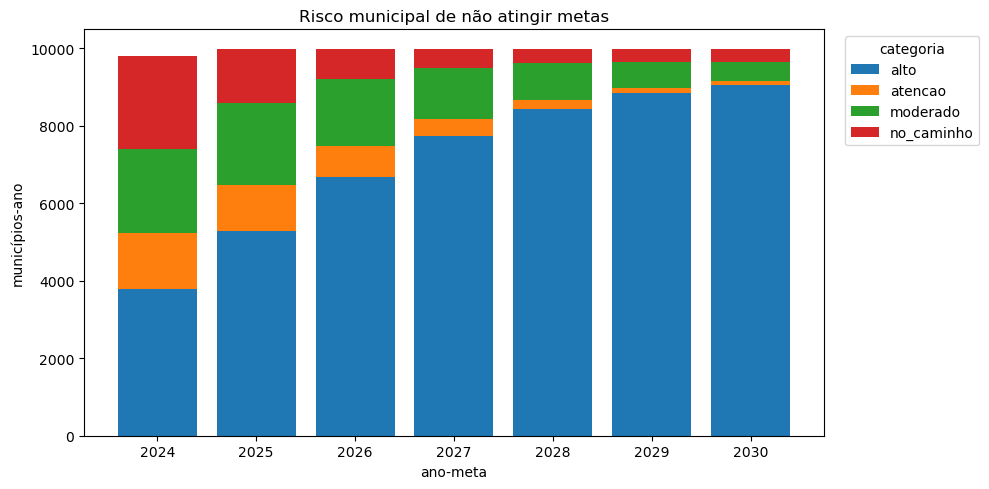

In [24]:
METAS_DIR = DADOS_PROCESSADOS_DIR / "preparado" / "metas_alfabetizacao_validadas"
metas = pl.scan_parquet(str(METAS_DIR / "**" / "*.parquet"), hive_partitioning=True).collect()
metas_municipais = metas.filter(pl.col("escopo_meta") == "municipio").with_columns(
    pl.col("id_municipio").cast(pl.Int64, strict=False),
    pl.col("rede").cast(pl.Int64, strict=False),
    pl.col("meta_alfabetizacao").cast(pl.Float64, strict=False),
)
mediana_meta = metas_municipais["meta_alfabetizacao"].drop_nulls().median()
metas_municipais = metas_municipais.with_columns(
    pl.col("meta_alfabetizacao").alias("meta_alfabetizacao_percentual"),
    (pl.col("meta_alfabetizacao") / 100 if mediana_meta and mediana_meta > 1 else pl.col("meta_alfabetizacao")).alias("meta_alfabetizacao"),
)
fora_intervalo = metas_municipais.filter(pl.col("meta_alfabetizacao").is_not_null() & ~pl.col("meta_alfabetizacao").is_between(0, 1))
if not fora_intervalo.is_empty():
    raise ValueError("Metas fora do intervalo probabilístico 0–1 após normalização.")

estimativas_municipais = municipios.with_columns(
    pl.col("id_municipio").cast(pl.Int64, strict=False), pl.col("rede").cast(pl.Int64, strict=False)
).filter(pl.col("rede") == 3)
risco_metas = estimativas_municipais.join(
    metas_municipais,
    left_on=["id_municipio", "sigla_uf", "rede", "ano_referencia"],
    right_on=["id_municipio", "sigla_uf", "rede", "ano_publicacao"],
    how="left",
)
risco_metas = risco_metas.with_columns(
    (pl.col("probabilidade_media") * (1 - pl.col("probabilidade_media")) / pl.col("registros").clip(lower_bound=1)).sqrt().alias("erro_padrao"),
    pl.when(pl.col("meta_alfabetizacao").is_not_null()).then(pl.lit("com_meta")).otherwise(pl.lit("sem_meta")).alias("cobertura_meta"),
).with_columns(
    (pl.col("probabilidade_media") - 1.96 * pl.col("erro_padrao")).clip(0, 1).alias("probabilidade_ic95_inferior"),
    (pl.col("probabilidade_media") + 1.96 * pl.col("erro_padrao")).clip(0, 1).alias("probabilidade_ic95_superior"),
    (pl.col("meta_alfabetizacao") - pl.col("probabilidade_media")).alias("deficit_meta"),
).with_columns(
    (100 * pl.col("deficit_meta")).alias("deficit_meta_pp"),
    pl.when(pl.col("meta_alfabetizacao").is_null()).then(pl.lit("sem_meta_correspondente"))
      .when(pl.col("deficit_meta") >= LIMITES_RISCO_META["alto"]).then(pl.lit("alto"))
      .when(pl.col("deficit_meta") >= LIMITES_RISCO_META["moderado"]).then(pl.lit("moderado"))
      .when(pl.col("deficit_meta") > LIMITES_RISCO_META["atencao"]).then(pl.lit("atencao"))
      .otherwise(pl.lit("no_caminho")).alias("categoria_risco"),
)
resumo_risco = risco_metas.group_by(["ano_referencia", "ano_meta", "categoria_risco"]).agg(
    pl.col("id_municipio").n_unique().alias("municipios"), pl.col("registros").sum().alias("alunos"),
    pl.col("deficit_meta_pp").mean().alias("deficit_medio_pp"),
)
cobertura_metas = risco_metas.group_by(["ano_referencia", "cobertura_meta"]).agg(
    pl.col("id_municipio").n_unique().alias("municipios")
)
risco_metas.write_csv(TABELAS_DIR / "11_risco_municipal_metas_2024_2030.csv")
resumo_risco.write_csv(TABELAS_DIR / "12_resumo_risco_metas.csv")
cobertura_metas.write_csv(TABELAS_DIR / "13_cobertura_metas.csv")
display(cobertura_metas, resumo_risco.head(30))
plot_risco = resumo_risco.drop_nulls(["ano_meta"])
categorias = plot_risco["categoria_risco"].unique().sort().to_list()
anos = plot_risco["ano_meta"].unique().sort().to_list()
fig, ax = plt.subplots(figsize=(10, 5)); base = np.zeros(len(anos))
for categoria in categorias:
    valores = [plot_risco.filter((pl.col("ano_meta") == ano) & (pl.col("categoria_risco") == categoria))["municipios"].sum() or 0 for ano in anos]
    ax.bar([str(a) for a in anos], valores, bottom=base, label=categoria); base += np.asarray(valores)
ax.set(xlabel="ano-meta", ylabel="municípios-ano", title="Risco municipal de não atingir metas")
ax.legend(title="categoria", bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout(); salvar_figura(fig, "09_risco_metas.png"); plt.show()


## 19. Respostas quantitativas e limitações

Esta tabela consolida o que o código efetivamente sustenta para cada pergunta norteadora.


In [25]:
top_features = fatores_associados.head(5)["feature"].to_list()
sem_meta_series = cobertura_metas.filter(pl.col("cobertura_meta") == "sem_meta")["municipios"]
sem_meta = int(sem_meta_series.max()) if len(sem_meta_series) else 0
rho_por_ano = "; ".join(
    f"{int(r['ano_referencia'])}: rho={r['spearman_target']:.3f}" for r in correlacao_inse.iter_rows(named=True)
)
silhouette_melhor = avaliacao_clusters.filter(pl.col("k") == melhor_k)["silhouette"][0]
respostas_norteadoras = pl.DataFrame([
    {"pergunta": "É possível prever alfabetização com os dados disponíveis?", "evidencia": f"ROC AUC={metricas_teste['roc_auc']:.4f}; AP={metricas_teste['average_precision']:.4f}; IC95% AUC={intervalos_95['roc_auc']['inferior']:.4f}–{intervalos_95['roc_auc']['superior']:.4f}", "interpretacao": "Existe sinal preditivo moderado, útil para análise agregada e priorização exploratória.", "limitacao": "Não autoriza decisão individual automatizada."},
    {"pergunta": "Quais fatores estão associados?", "evidencia": ", ".join(top_features), "interpretacao": "São os sinais que mais sustentam a discriminação do modelo.", "limitacao": "Importância preditiva não implica direção nem causalidade."},
    {"pergunta": "Quanto o desempenho depende de sigla_uf?", "evidencia": f"Δ ROC AUC com−sem UF={metricas_teste['roc_auc'] - metricas_teste_sem_uf['roc_auc']:.4f}; Δ AP={metricas_teste['average_precision'] - metricas_teste_sem_uf['average_precision']:.4f}", "interpretacao": "A comparação quantifica a informação territorial adicional sob o mesmo protocolo e hiperparâmetros.", "limitacao": "UF é proxy de políticas, investimento, infraestrutura e contexto regional; a diferença não é causal."},
    {"pergunta": "Infraestrutura está associada?", "evidencia": f"{infraestrutura.height:,} combinações avaliadas.", "interpretacao": "As tabelas por faixa permitem comparar taxas observadas e estimadas.", "limitacao": "Infraestrutura municipal agregada, não da escola frequentada."},
    {"pergunta": "INSE está associado?", "evidencia": rho_por_ano, "interpretacao": "A direção e a magnitude são apresentadas separadamente por ano.", "limitacao": "INSE municipal de 2023, não individual."},
    {"pergunta": "Há persistência entre 2023 e 2024?", "evidencia": f"rho observado={persistencia['spearman_observado_2023_2024']:.3f}; pares={persistencia['municipios_redes_comparaveis']:,}", "interpretacao": "Mede persistência municipal de curto prazo.", "limitacao": "Dois anos não formam tendência histórica longa; SP não possui 2023."},
    {"pergunta": "Finanças estão associadas?", "evidencia": f"{financeiro.height:,} combinações avaliadas.", "interpretacao": "As diferenças são associações preditivas condicionadas ao conjunto disponível.", "limitacao": "Totais podem representar porte; não equivalem a gasto educacional por aluno."},
    {"pergunta": "Existem perfis municipais?", "evidencia": f"k={melhor_k}; silhouette={silhouette_melhor:.3f}", "interpretacao": "Os clusters resumem perfis contextuais semelhantes.", "limitacao": "Clusters são descritivos, dependem das variáveis e não representam causas."},
    {"pergunta": "Quais municípios têm risco de não atingir metas?", "evidencia": f"Tabela de risco produzida; até {sem_meta} municípios por ano sem correspondência.", "interpretacao": "Déficit positivo indica estimativa abaixo da meta no cenário observado.", "limitacao": "Não é projeção temporal completa; incerteza é aproximação binomial agregada."},
])
respostas_norteadoras.write_csv(TABELAS_DIR / "14_respostas_norteadoras.csv")
display(respostas_norteadoras)


pergunta,evidencia,interpretacao,limitacao
str,str,str,str
"""É possível prever alfabetizaçã…","""ROC AUC=0.6705; AP=0.6841; IC9…","""Existe sinal preditivo moderad…","""Não autoriza decisão individua…"
"""Quais fatores estão associados…","""sigla_uf, valor_bolsa_familia_…","""São os sinais que mais sustent…","""Importância preditiva não impl…"
"""Quanto o desempenho depende de…","""Δ ROC AUC com−sem UF=-0.0052; …","""A comparação quantifica a info…","""UF é proxy de políticas, inves…"
"""Infraestrutura está associada?""","""77 combinações avaliadas.""","""As tabelas por faixa permitem …","""Infraestrutura municipal agreg…"
"""INSE está associado?""","""2024: rho=0.024; 2023: rho=0.0…","""A direção e a magnitude são ap…","""INSE municipal de 2023, não in…"
"""Há persistência entre 2023 e 2…","""rho observado=0.447; pares=5,6…","""Mede persistência municipal de…","""Dois anos não formam tendência…"
"""Finanças estão associadas?""","""40 combinações avaliadas.""","""As diferenças são associações …","""Totais podem representar porte…"
"""Existem perfis municipais?""","""k=3; silhouette=0.240""","""Os clusters resumem perfis con…","""Clusters são descritivos, depe…"
"""Quais municípios têm risco de …","""Tabela de risco produzida; até…","""Déficit positivo indica estima…","""Não é projeção temporal comple…"


## 11. SHAP — explicação complementar controlada

O SHAP é usado como complemento global da importância por permutação. Para manter a execução viável em computadores modestos, ele é desativado por padrão e usa uma amostra pequena quando habilitado. Ative com `TC3_EXECUTAR_SHAP=1`; ajuste `TC3_AMOSTRA_SHAP` e `TC3_BACKGROUND_SHAP` se necessário.

As explicações continuam associativas: valores SHAP mostram contribuições à predição do modelo, não efeitos causais.


/opt/conda/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[cuml.accel] `RandomForestClassifier.predict_proba` ran on GPU
[cuml.accel] `RandomForestClassifier.predict_proba` ran on GPU
[cuml.accel] `RandomForestClassifier.predict_proba` ran on GPU
[cuml.accel] `RandomForestClassifier.predict_proba` ran on GPU
[cuml.accel] `RandomForestClassifier.predict_proba` ran on GPU
[cuml.accel] `RandomForestClassifier.predict_proba` ran on GPU
[cuml.accel] `RandomForestClassifier.predict_proba` ran on GPU
[cuml.accel] `RandomForestClassifier.predict_proba` ran on GPU
[cuml.accel] `RandomForestClassifier.predict_proba` ran on GPU
[cuml.accel] `RandomForestClassifier.predict_proba` ran on GPU
[cuml.accel] `RandomForestClassifier.predict_proba` ran on GPU
[cuml.accel] `RandomForestClassifier.predict_proba` ran on GPU
[cuml.accel] `RandomForestClassifier.predict_proba` ran on GPU
[cuml.accel] `RandomForestClassifier.predict_proba` ran on GPU
[cuml.accel] `RandomForestClassifier.predict_proba` ran on GPU
[cuml.accel] `RandomForestClassifier.predict_proba` ran

feature,shap_abs_medio
str,f64
"""sigla_uf""",0.105783
"""valor_bolsa_familia__signed_lo…",0.020112
"""media_inse""",0.012066
"""valor_receitas__signed_log1p""",0.009798
"""in_internet""",0.007418
…,…
"""ano_referencia""",0.003678
"""in_esgoto_rede_publica""",0.003298
"""in_banda_larga""",0.002039


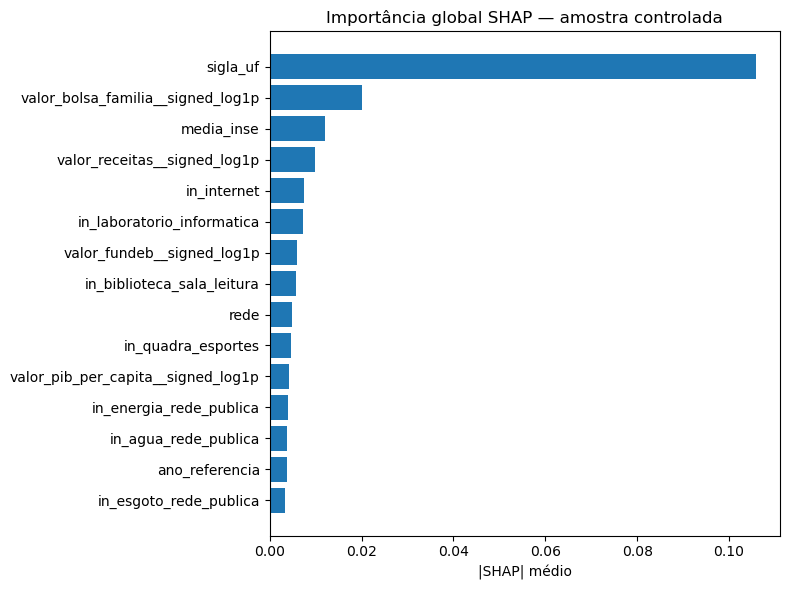

SHAP corrigido e salvo com os nomes originais: 18 features.


In [26]:
import re

shap_resultados = pl.DataFrame({
    "feature": pl.Series([], dtype=pl.String),
    "shap_abs_medio": pl.Series([], dtype=pl.Float64),
})

if not EXECUTAR_SHAP:
    print(
        "SHAP não executado. Defina TC3_EXECUTAR_SHAP=1 "
        "antes de iniciar o kernel para habilitar."
    )
else:
    try:
        import shap
    except ImportError as exc:
        raise ImportError(
            "Instale as dependências do projeto para executar SHAP."
        ) from exc

    # Seleção determinística da amostra.
    rng_shap = np.random.default_rng(SEED)
    n_shap = min(AMOSTRA_SHAP, len(y_test))
    indices_shap = rng_shap.choice(
        len(y_test),
        size=n_shap,
        replace=False,
    )
    X_shap_original = X_test[indices_shap.tolist(), :]

    # Reutiliza o preprocessador e o estimador do modelo oficial já treinado.
    preprocessador_final = modelo.named_steps["preprocessor"]
    estimador_final = modelo.named_steps["model"]

    X_shap_transformado = np.asarray(
        preprocessador_final.transform(X_shap_original)
    )

    nomes_transformados = [
        nome.split("__", 1)[-1]
        for nome in preprocessador_final.get_feature_names_out()
    ]

    n_background = min(
        AMOSTRA_BACKGROUND_SHAP,
        X_shap_transformado.shape[0],
    )
    background = X_shap_transformado[:n_background]

    def prever_classe_positiva(matriz):
        return np.asarray(
            estimador_final.predict_proba(matriz)
        )[:, 1]

    explicador_shap = shap.Explainer(
        prever_classe_positiva,
        background,
        algorithm="permutation",
        seed=SEED,
    )

    explicacao_shap = explicador_shap(
        X_shap_transformado,
        max_evals=2 * X_shap_transformado.shape[1] + 1,
    )

    valores_abs = np.abs(
        np.asarray(explicacao_shap.values)
    ).mean(axis=0)

    def feature_original(nome_transformado):
        """
        Reconstrói a feature original a partir dos nomes x0, x1, x2...
        produzidos pelo ColumnTransformer com seletores posicionais.

        Exemplos:
        x0_CE -> sigla_uf
        x0_SP -> sigla_uf
        x1_2  -> rede
        x2    -> ano_referencia
        """
        nome_limpo = nome_transformado.split("__", 1)[-1]

        correspondencia = re.match(
            r"^x(\d+)(?:_.*)?$",
            nome_limpo,
        )

        if correspondencia:
            indice = int(correspondencia.group(1))

            if 0 <= indice < len(FEATURES):
                return FEATURES[indice]

        # Fallback para versões que preservem os nomes originais.
        for feature in sorted(FEATURES, key=len, reverse=True):
            if (
                nome_limpo == feature
                or nome_limpo.startswith(feature + "_")
            ):
                return feature

        return nome_limpo

    # Soma as importâncias das categorias provenientes da mesma feature.
    agregados_shap = {}

    for nome, valor in zip(nomes_transformados, valores_abs):
        original = feature_original(nome)

        agregados_shap[original] = (
            agregados_shap.get(original, 0.0)
            + float(valor)
        )

    shap_resultados = (
        pl.DataFrame({
            "feature": list(agregados_shap),
            "shap_abs_medio": list(agregados_shap.values()),
        })
        .sort("shap_abs_medio", descending=True)
    )

    display(shap_resultados)

    # Gráfico com as 15 features mais importantes.
    top_shap = (
        shap_resultados
        .head(15)
        .sort("shap_abs_medio")
    )

    plt.figure(figsize=(8, 6))
    plt.barh(
        top_shap["feature"],
        top_shap["shap_abs_medio"],
    )
    plt.xlabel("|SHAP| médio")
    plt.title("Importância global SHAP — amostra controlada")
    plt.tight_layout()

    salvar_figura_eda(
        plt.gcf(),
        "avaliacao_final_shap_global.png",
    )
    plt.show()

    # Salva imediatamente o resultado corrigido, sem depender das
    # células posteriores do notebook.
    RESULTADOS_TABELAS_DIR.mkdir(
        parents=True,
        exist_ok=True,
    )

    shap_resultados.write_csv(
        RESULTADOS_TABELAS_DIR
        / "19_importancia_shap.csv"
    )

    print(
        "SHAP corrigido e salvo com os nomes originais:",
        shap_resultados.height,
        "features."
    )

## 21. Auditoria, reprodutibilidade e status da execução

O encerramento valida os artefatos obrigatórios, registra versões e atualiza o status do fluxo oficial. O arquivo de ambiente não substitui um teste posterior em máquina limpa, mas torna a execução auditável.


In [27]:
politica_temporal_fontes.write_csv(TABELAS_DIR / "15_politica_temporal_fontes.csv")
auditoria_cobertura_fontes.write_csv(TABELAS_DIR / "16_auditoria_cobertura_fontes.csv")
diagnostico_uf.write_csv(TABELAS_DIR / "17_diagnostico_proxy_uf.csv")
sensibilidade_uf.write_csv(TABELAS_DIR / "18_sensibilidade_sigla_uf.csv")
if not shap_resultados.is_empty():
    shap_resultados.write_csv(TABELAS_DIR / "19_importancia_shap.csv")

artefatos_obrigatorios = [
    METRICAS_FINAIS_DIR / "resultado_final.json",
    MODEL_DIR / "modelo_pipeline.joblib",
    ANALITICOS_FINAIS_DIR / "predicoes_agregadas_municipio.parquet",
    TABELAS_DIR / "01_fatores_associados.csv",
    TABELAS_DIR / "11_risco_municipal_metas_2024_2030.csv",
    TABELAS_DIR / "14_respostas_norteadoras.csv",
    TABELAS_DIR / "15_politica_temporal_fontes.csv",
    TABELAS_DIR / "16_auditoria_cobertura_fontes.csv",
    TABELAS_DIR / "17_diagnostico_proxy_uf.csv",
    TABELAS_DIR / "18_sensibilidade_sigla_uf.csv",
    FIGURAS_DIR / "01_metricas_classificacao.png",
    FIGURAS_DIR / "09_risco_metas.png",
]
faltantes = [str(p.relative_to(PROJECT_ROOT)) for p in artefatos_obrigatorios if not p.exists()]
if faltantes:
    raise FileNotFoundError(f"Artefatos obrigatórios ausentes: {faltantes}")

ambiente_final = {
    "gerado_em_utc": datetime.now(timezone.utc).isoformat(),
    "python": platform.python_version(),
    "scikit_learn": sklearn.__version__,
    "polars": pl.__version__,
    "backend_ml": BACKEND_ML,
    "seed": SEED,
    "modelo": "Random Forest",
    "parametros": parametros,
    "features": FEATURES,
    "teste_reutilizado_para_tuning": False,
    "politica_temporal_fontes": politica_temporal_fontes.to_dicts(),
    "sensibilidade_sigla_uf": sensibilidade_uf.to_dicts(),
    "shap_executado": bool(EXECUTAR_SHAP),
    "amostra_shap": int(AMOSTRA_SHAP) if EXECUTAR_SHAP else 0,
}
(ANALISE_DIR / "ambiente_execucao.json").write_text(json.dumps(ambiente_final, ensure_ascii=False, indent=2), encoding="utf-8")

status = {
    "estado": "concluido",
    "finalizado_em_utc": datetime.now(timezone.utc).isoformat(),
    "fluxo": "TC3_Pipeline_Completo_Alfabetizacao.ipynb",
    "backend_ml": BACKEND_ML,
    "modelo_oficial": "Random Forest",
    "roc_auc_teste": metricas_teste["roc_auc"],
    "artefatos_validados": len(artefatos_obrigatorios),
    "erro": None,
}
STATUS_PATH = RESULTADOS_RELATORIOS_DIR / "status_execucao.json"
STATUS_PATH.parent.mkdir(parents=True, exist_ok=True)
STATUS_PATH.write_text(json.dumps(status, ensure_ascii=False, indent=2), encoding="utf-8")
print("Auditoria concluída:", len(artefatos_obrigatorios), "artefatos obrigatórios validados.")


Auditoria concluída: 12 artefatos obrigatórios validados.


<a id="conclusao"></a>

## 22. Conclusão dinâmica

A célula abaixo monta a conclusão diretamente a partir dos resultados desta execução. Isso evita manter números antigos em texto estático.


In [28]:
auc_ic = intervalos_95["roc_auc"]
melhor_silhouette = avaliacao_clusters.filter(pl.col("k") == melhor_k)["silhouette"][0]
conclusao = (
    "## Conclusão da entrega analítica\n\n"
    f"O Random Forest, selecionado antes do acesso ao teste, foi avaliado em **{len(y_test):,} registros** e obteve "
    f"**ROC AUC {metricas_teste['roc_auc']:.4f}** (IC95% **{auc_ic['inferior']:.4f}–{auc_ic['superior']:.4f}**), "
    f"**Average Precision {metricas_teste['average_precision']:.4f}**, **Balanced Accuracy {metricas_teste['balanced_accuracy']:.4f}** "
    f"e **F1 {metricas_teste['f1']:.4f}**. O desempenho é superior ao acaso, porém moderado, e sustenta análises agregadas — "
    "não decisões individuais automatizadas.\n\n"
    f"As variáveis com maior importância preditiva foram **{', '.join(top_features)}**. Elas representam sinais predominantemente "
    "territoriais e contextuais; nenhuma delas deve ser interpretada como causa da alfabetização. "
    f"Na análise de sensibilidade, retirar `sigla_uf` alterou o ROC AUC em **{metricas_teste['roc_auc'] - metricas_teste_sem_uf['roc_auc']:.4f}** "
    f"e a Average Precision em **{metricas_teste['average_precision'] - metricas_teste_sem_uf['average_precision']:.4f}**. "
    "Isso quantifica dependência preditiva do contexto territorial, não efeito causal da UF.\n\n"
    f"A persistência municipal entre 2023 e 2024 foi calculada em **{persistencia['municipios_redes_comparaveis']:,} pares município-rede "
    f"comparáveis**, com correlação de Spearman observada de **{persistencia['spearman_observado_2023_2024']:.3f}**. Essa evidência descreve "
    "persistência de curto prazo, não tendência histórica longa.\n\n"
    f"A análise territorial identificou **{melhor_k} perfis contextuais municipais** (silhouette **{melhor_silhouette:.3f}**). "
    "Os grupos são descritivos e não representam mecanismos causais.\n\n"
    "As estimativas municipais foram comparadas às metas oficiais no mesmo município, rede e publicação. O déficit é definido como meta "
    "menos probabilidade média. Categorias de risco e cobertura foram exportadas, incluindo territórios sem correspondência de meta. "
    "As metas futuras são cenários condicionais ao contexto observado, não projeções completas até 2030.\n\n"
    f"O treinamento final levou **{tempo_treino / 60:.1f} minutos** e a inferência **{tempo_inferencia:.2f} segundos**, usando "
    f"**{BACKEND_ML}**. O conjunto de teste não foi utilizado para alterar features, algoritmo, hiperparâmetros ou limiar."
)
display(Markdown(conclusao))
(ANALISE_DIR / "conclusao_dinamica.md").write_text(conclusao, encoding="utf-8")


## Conclusão da entrega analítica

O Random Forest, selecionado antes do acesso ao teste, foi avaliado em **581,591 registros** e obteve **ROC AUC 0.6705** (IC95% **0.6673–0.6737**), **Average Precision 0.6841**, **Balanced Accuracy 0.6196** e **F1 0.6392**. O desempenho é superior ao acaso, porém moderado, e sustenta análises agregadas — não decisões individuais automatizadas.

As variáveis com maior importância preditiva foram **sigla_uf, valor_bolsa_familia__signed_log1p, media_inse, rede, in_laboratorio_informatica**. Elas representam sinais predominantemente territoriais e contextuais; nenhuma delas deve ser interpretada como causa da alfabetização. Na análise de sensibilidade, retirar `sigla_uf` alterou o ROC AUC em **-0.0052** e a Average Precision em **-0.0069**. Isso quantifica dependência preditiva do contexto territorial, não efeito causal da UF.

A persistência municipal entre 2023 e 2024 foi calculada em **5,653 pares município-rede comparáveis**, com correlação de Spearman observada de **0.447**. Essa evidência descreve persistência de curto prazo, não tendência histórica longa.

A análise territorial identificou **3 perfis contextuais municipais** (silhouette **0.240**). Os grupos são descritivos e não representam mecanismos causais.

As estimativas municipais foram comparadas às metas oficiais no mesmo município, rede e publicação. O déficit é definido como meta menos probabilidade média. Categorias de risco e cobertura foram exportadas, incluindo territórios sem correspondência de meta. As metas futuras são cenários condicionais ao contexto observado, não projeções completas até 2030.

O treinamento final levou **1.3 minutos** e a inferência **0.58 segundos**, usando **RAPIDS cuML — NVIDIA GeForce RTX 3050 6GB Laptop GPU (6.0 GB de VRAM)**. O conjunto de teste não foi utilizado para alterar features, algoritmo, hiperparâmetros ou limiar.

1886

<a id="encerramento"></a>

# Encerramento

Ao fim da execução, o pipeline oficial fica em `modelos/random_forest/`; métricas, figuras, tabelas e relatórios ficam em `resultados/`; e previsões agregadas ficam em `dados/dados_analiticos/`. As fontes originais não são modificadas.

A interpretação oficial não compara modelos no teste: a escolha do Random Forest ocorre na Fase 6, usando validação; a Fase 7 estima o desempenho final do candidato previamente selecionado.
